# Sesión 3 — MUBD

## Modelo lineal: de los datos a la predicción

**Pregunta:** ¿cómo cambia la resistencia del hormigón (`Strength`) con su composición y su edad? Seguiremos un mismo conjunto de datos desde la exploración hasta la evaluación con observaciones que el modelo no ha visto. El recorrido es: **describir → ajustar → seleccionar → diagnosticar → transformar → interpretar → evaluar en test**. Un buen ajuste en entrenamiento no implica necesariamente buenas predicciones fuera de él.

En VS Code, selecciona un kernel de Python y ejecuta las celdas **en orden** con **Shift + Enter**. Abre **Variables** para inspeccionar tablas y **Esquema / Outline** para navegar por apartados. Cada celda depende de las definiciones anteriores; si aparece una variable no definida, ejecuta las celdas previas. Los gráficos se generan al ejecutar sus celdas; cambia los argumentos de las funciones y vuelve a ejecutarlas para comparar escenarios.

Para repetir todo el análisis, usa **Reiniciar** y **Ejecutar todo**. [Guía de notebooks en VS Code](https://code.visualstudio.com/docs/datascience/jupyter-notebooks).

Los **microejercicios** intercalados piden **una sola línea de código**: escríbela en la siguiente celda Python y razona la respuesta antes de continuar. Los ejercicios 3.1 y 3.2 dejan más tiempo para aplicar el procedimiento completo. Conserva `datos`, los modelos y las predicciones originales: las celdas siguientes los reutilizan. El modelo final se elige con entrenamiento; el test se reserva para la evaluación.

### Preparación

Importamos NumPy para cálculo numérico, pandas para las tablas, Matplotlib para los gráficos, statsmodels para el ajuste y los diagnósticos, SciPy para contrastes y transformaciones, y `threadpoolctl` para limitar los hilos durante la selección. Más adelante se usa `ipywidgets` para explorar una predicción individual.

**Antes de ejecutar:** prepara el entorno según la guía de la raíz del proyecto y selecciona en VS Code el **kernel de ese mismo entorno**. Instalar una biblioteca en otro intérprete no resuelve errores de importación en este cuaderno. La configuración de Matplotlib fija un tamaño inicial de figura; cada gráfico puede indicar otro tamaño si necesita más espacio.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display
from pandas.plotting import scatter_matrix
from scipy import stats
from scipy.optimize import minimize_scalar
from scipy.special import boxcox
from statsmodels.nonparametric.smoothers_lowess import lowess
from threadpoolctl import threadpool_limits

%matplotlib inline
%config InteractiveShell.ast_node_interactivity = "all"
plt.rcParams.update({"figure.figsize": (16, 8), "figure.dpi": 100,
                     "axes.titlesize": 20, "axes.labelsize": 16,
                     "xtick.labelsize": 14, "ytick.labelsize": 14})
pd.set_option("display.max_columns", 20)

## Lectura de datos y descriptiva

Leemos el archivo de entrenamiento con `sep="\t"`: los campos están separados por tabuladores y la primera fila contiene sus nombres. El bucle busca la carpeta de datos desde el directorio actual hacia sus padres; así no depende de ejecutar el cuaderno desde una única ruta. Si no encuentra el archivo, muestra un error explícito.

Tras cargarlo, asignamos etiquetas de fila de 1 a $n$ y el nombre `observacion`. **Son identificadores para localizar casos, no fechas ni un orden de recogida demostrado.** Guardamos los nombres originales antes de crear variables nuevas: `Strength` será la respuesta $y$ y las ocho columnas restantes serán las predictoras $X$. Más adelante esas listas permiten comparar y mostrar los datos originales sin mezclar transformaciones.

In [2]:
for carpeta in (Path.cwd(), *Path.cwd().parents):
    if (carpeta / "datos" / "Concrete_train.txt").is_file():
        DATA_PATH = carpeta / "datos"
        break
else:
    raise FileNotFoundError("Abre el notebook dentro de la carpeta LaSalle_Estadistica.")

datos = pd.read_csv(DATA_PATH / "Concrete_train.txt", sep="\t")
datos.index = np.arange(1, len(datos) + 1)
datos.index.name = "observacion"
columnas_originales = list(datos.columns)
predictores = [columna for columna in datos if columna != "Strength"]

### Inspección inicial

Ejecuta las tres celdas siguientes en orden:

1. `datos.shape` devuelve **(filas, columnas)**: comprueba cuántos casos y variables tenemos antes de ajustar modelos.
2. `datos` muestra las observaciones; comprueba nombres, unidades y posibles valores ausentes o inesperados. Las etiquetas empiezan en 1; `datos.loc[[5]]` seleccionaría el caso etiquetado 5, no la quinta posición por otra convención.
3. `datos.describe()` resume, para cada variable numérica, recuento, media, desviación típica, mínimo, cuartiles y máximo. Compara escalas y rangos; el recuento puede revelar datos faltantes, pero un resumen agregado no muestra todas las relaciones entre variables.

**Antes de modelizar**, pregúntate qué columna queremos predecir y si las variables de entrada podrían contener valores extremos o relaciones no lineales.

In [3]:
datos.shape  # Número de filas y columnas

(706, 9)

In [4]:
datos

,Cement,BlastFurnaceSlag,FlyAsh,Water,Superplasticizer,CoarseAggregate,FineAggregate,Age,Strength
observacion,,,,,,,,,
1,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30
2,266.0,114.0,0.0,228.0,0.0,932.0,670.0,90,47.03
3,380.0,95.0,0.0,228.0,0.0,932.0,594.0,365,43.70
4,380.0,95.0,0.0,228.0,0.0,932.0,594.0,28,36.45
5,198.6,132.4,0.0,192.0,0.0,978.4,825.5,90,38.07
...,...,...,...,...,...,...,...,...,...
702,264.5,111.0,86.5,195.5,5.9,832.6,790.4,28,41.54
703,159.8,250.0,0.0,168.4,12.2,1049.3,688.2,28,39.46
704,322.2,0.0,115.6,196.0,10.4,817.9,813.4,28,31.18


In [5]:
datos.describe()

,Cement,BlastFurnaceSlag,FlyAsh,Water,Superplasticizer,CoarseAggregate,FineAggregate,Age,Strength
count,706.000000,706.000000,706.000000,706.000000,706.000000,706.000000,706.000000,706.000000,706.000000
mean,278.143626,73.110623,54.056799,182.512040,6.092068,972.776771,773.025496,45.440510,35.209476
std,101.572253,85.661802,64.505534,20.833819,5.806369,77.753339,79.565862,62.752333,16.427955
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,190.700000,0.000000,0.000000,167.925000,0.000000,932.000000,728.225000,14.000000,23.427500
50%,269.300000,22.000000,0.000000,185.700000,6.400000,968.000000,778.500000,28.000000,33.710000
75%,347.250000,140.975000,118.300000,192.000000,10.000000,1030.000000,824.750000,56.000000,44.610000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


#### Diagramas de caja de todas las variables

Cada caja va del primer al tercer cuartil y la línea interior marca la mediana; los bigotes y los puntos separados ayudan a detectar observaciones alejadas del grueso. Los gráficos se dibujan **en la escala original de cada columna**, por lo que una variable con valores numéricamente grandes puede comprimir visualmente otras cajas: no compares alturas entre variables con unidades o rangos distintos como si midieran lo mismo.

Un valor que parece atípico no es automáticamente un error. Anótalo para revisarlo junto con el resto de variables y los diagnósticos del modelo. Giramos las etiquetas del eje horizontal para poder leer todos los nombres.

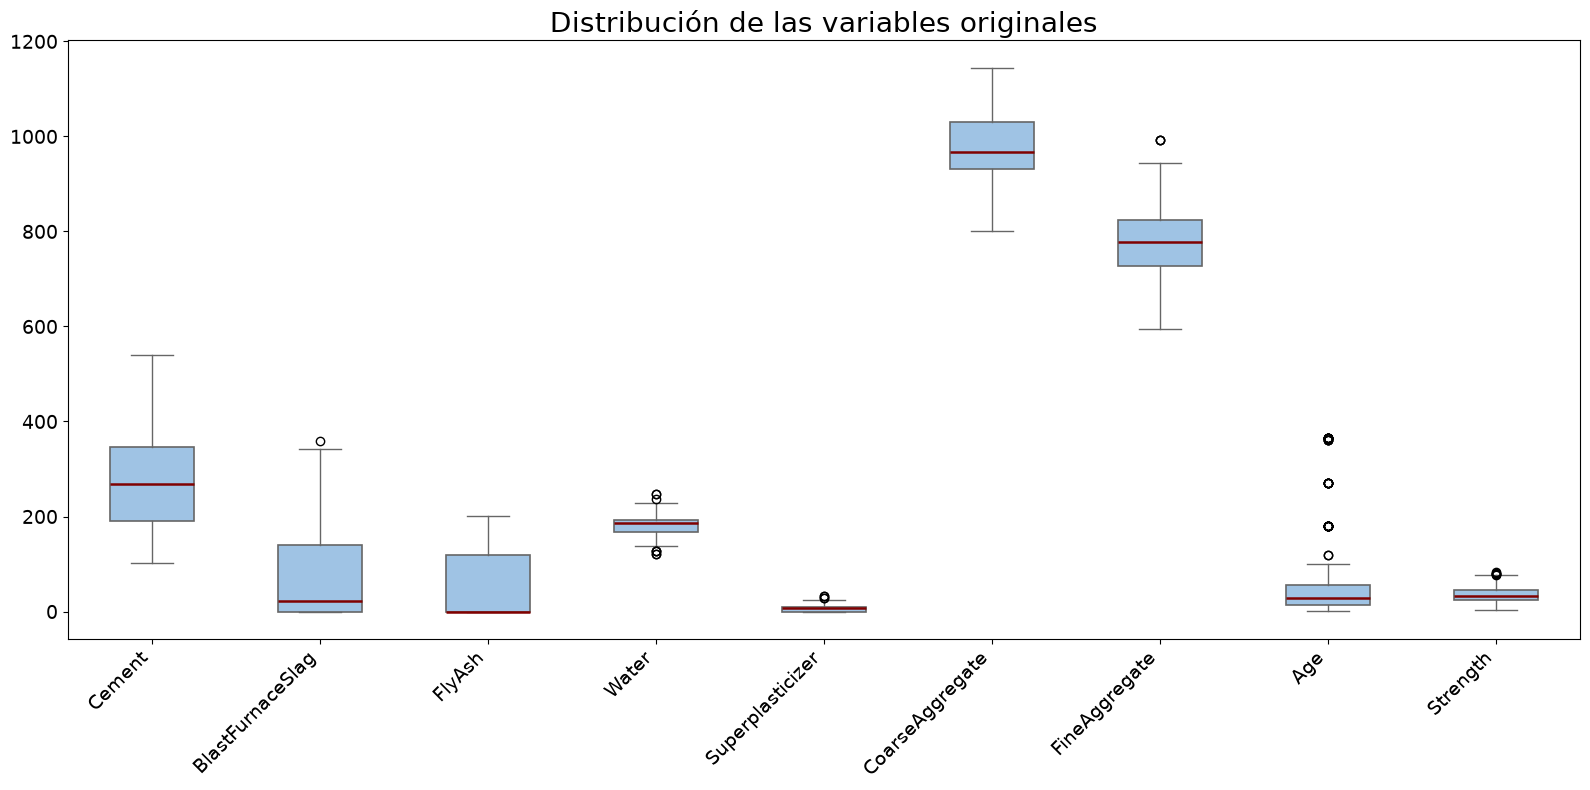

In [6]:
fig, ax = plt.subplots(figsize=(16, 8))
_ = ax.boxplot([datos[columna].dropna() for columna in columnas_originales],
               patch_artist=True,
               boxprops={"facecolor": "#9fc3e4", "edgecolor": "#666666", "linewidth": 1.2},
               whiskerprops={"color": "#666666"}, capprops={"color": "#666666"},
               medianprops={"color": "#800000", "linewidth": 1.8})
_ = ax.set_xticks(np.arange(1, len(columnas_originales) + 1))
_ = ax.set_xticklabels(columnas_originales, rotation=45, ha="right")
_ = ax.set_title("Distribución de las variables originales")
ax.tick_params(labelsize=14)
fig.tight_layout()
plt.show()

#### Explorar todos los pares de variables

La matriz de dispersión reúne un gráfico por pareja de columnas: en la diagonal hay histogramas y fuera de ella, nubes de puntos. Busca asociaciones entre `Strength` y las predictoras, posibles curvas, grupos y también relaciones fuertes **entre predictoras** que puedan dificultar la interpretación de coeficientes. El mismo par aparece reflejado a ambos lados de la diagonal, con los ejes intercambiados.

Este gráfico es **exploratorio**: una nube con forma de curva sugiere probar otra especificación, no demuestra que exista una relación causal. La transparencia evita que la superposición de muchos puntos oculte por completo su densidad.

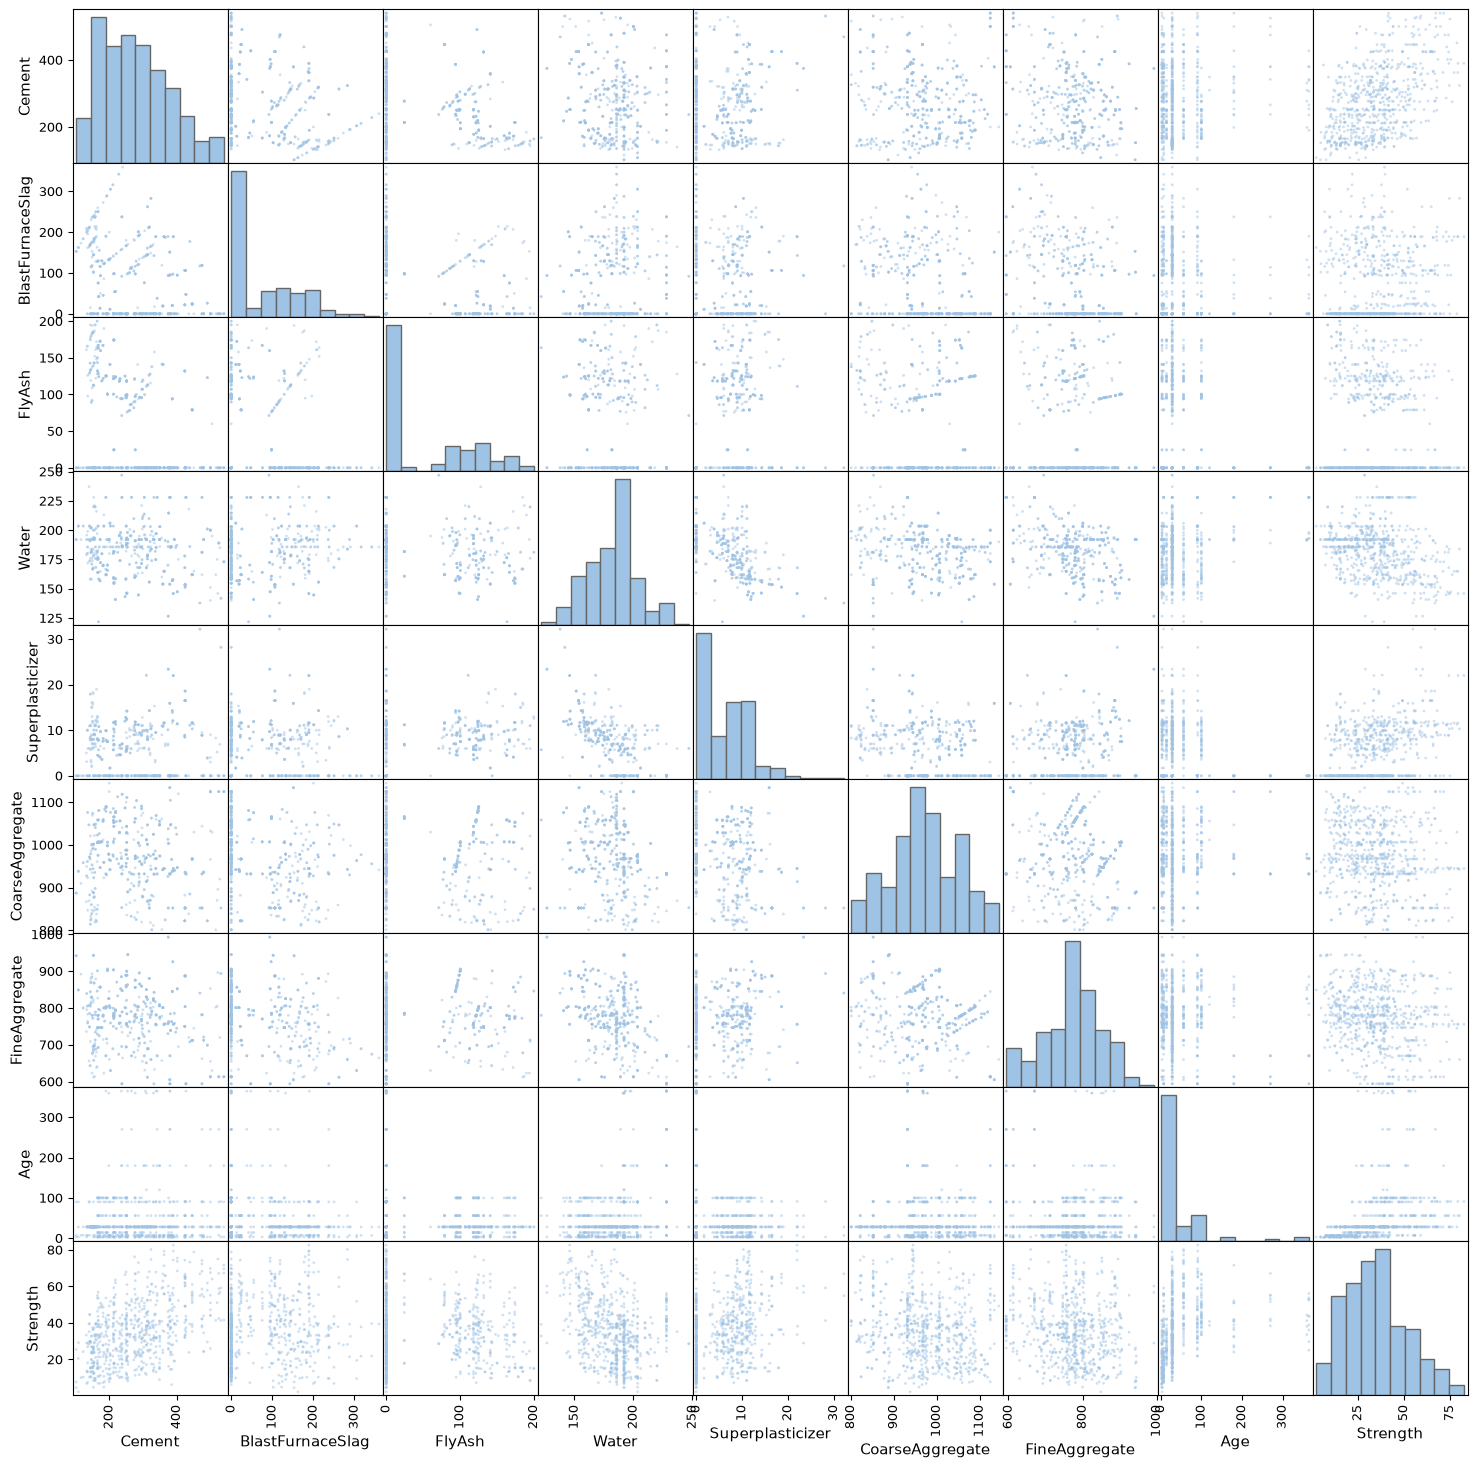

In [7]:
axes = scatter_matrix(datos[columnas_originales], figsize=(18, 18), diagonal="hist",
                      color="#9fc3e4", alpha=0.5, s=16,
                      hist_kwds={"color": "#9fc3e4", "edgecolor": "#666666"})
for ax in axes.flat:
    ax.tick_params(labelsize=9)
    ax.xaxis.label.set_fontsize(11)
    ax.yaxis.label.set_fontsize(11)
plt.show()

### Relación entre resistencia y cemento

Los puntos muestran cada par (`Cement`, `Strength`); la curva **LOWESS** resume la tendencia local sin obligarla a ser una recta. `fraccion` controla aproximadamente qué proporción de observaciones contribuye a cada ajuste local: una fracción menor sigue más los detalles y también el ruido, y una mayor suaviza más. Prueba con otro predictor o cambia la fracción en la llamada siguiente para comparar.

La función detecta avisos numéricos o valores no finitos y, si hace falta, amplía el vecindario en incrementos pequeños; indica en el gráfico la fracción finalmente utilizada. **Cómo leerlo:** si la pendiente cambia claramente a lo largo del eje horizontal, un único coeficiente lineal podría no describir toda la relación. LOWESS ayuda a proponer modelos; no sustituye su validación.

In [8]:
def dibujar_relacion(ax, x, y, nombre, fraccion=2/3):
    ax.scatter(x, y, s=30, color="#9fc3e4", edgecolor="#666666",
               linewidth=0.4, alpha=0.6)
    aplicada = fraccion
    while True:
        with warnings.catch_warnings(record=True) as avisos:
            warnings.simplefilter("always", RuntimeWarning)
            curva = lowess(y, x, frac=aplicada, it=3, delta=0.01 * np.ptp(x))
        numericos = any(issubclass(aviso.category, RuntimeWarning) for aviso in avisos)
        if np.isfinite(curva).all() and not numericos:
            break
        if aplicada >= 1:
            raise ValueError("No se puede estimar LOWESS con estos valores.")
        aplicada = min(1, aplicada + 0.05)
    ax.plot(curva[:, 0], curva[:, 1], color="#800000", linewidth=1.8)
    ax.set(xlabel=nombre, ylabel="Strength")
    if aplicada > fraccion + 1e-8:
        ax.text(0.02, 0.98, f"Fracción aplicada: {aplicada:.2f}",
                transform=ax.transAxes, va="top", fontsize=11)

def explorar_relacion(variable, fraccion):
    fig, ax = plt.subplots(figsize=(16, 8))
    dibujar_relacion(ax, datos[variable], datos["Strength"], variable, fraccion)
    ax.set_title("Resistencia y " + variable)
    fig.tight_layout()
    plt.show()

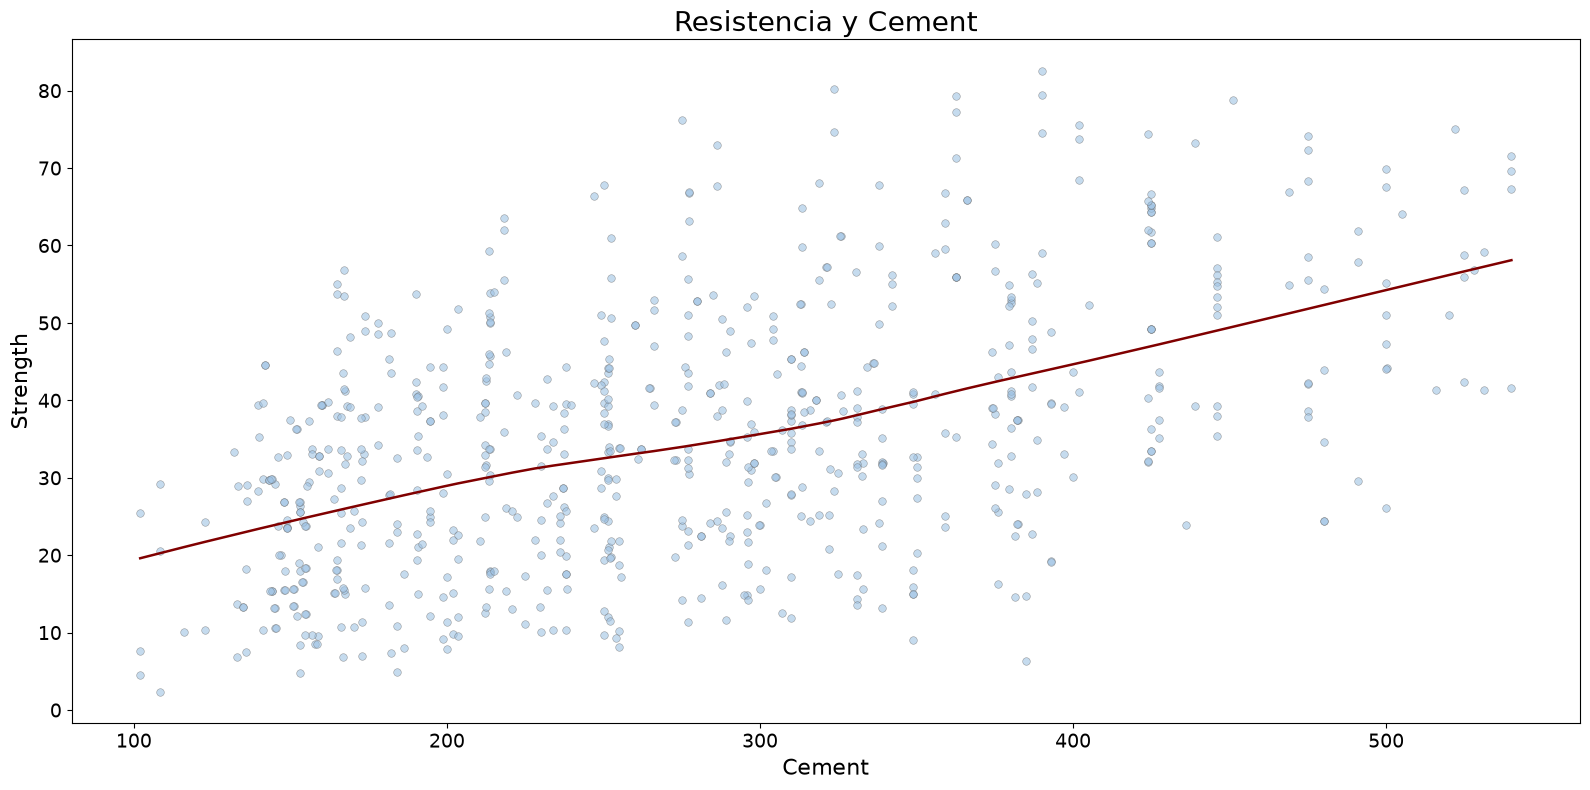

In [9]:
# Cambia "Cement" por otro predictor o ajusta la fracción para comparar curvas.
explorar_relacion("Cement", 2/3)

#### Descriptiva bivariante para las ocho variables predictoras

Repetimos la nube de puntos y el suavizado LOWESS para cada predictor frente a `Strength`. Observa en qué variables la tendencia parece casi recta, en cuáles se curva y en cuáles se acumulan muchos casos en un mismo valor (por ejemplo, ceros). También importa si la dispersión vertical cambia al aumentar la variable.

**Precaución:** cada panel es una relación *marginal*, sin mantener constantes las otras siete variables. Un patrón puede cambiar al ajustar conjuntamente; no interpretes estas curvas como efectos aislados. La comparación sirve para decidir qué revisar en los residuos y si merece la pena considerar términos no lineales.

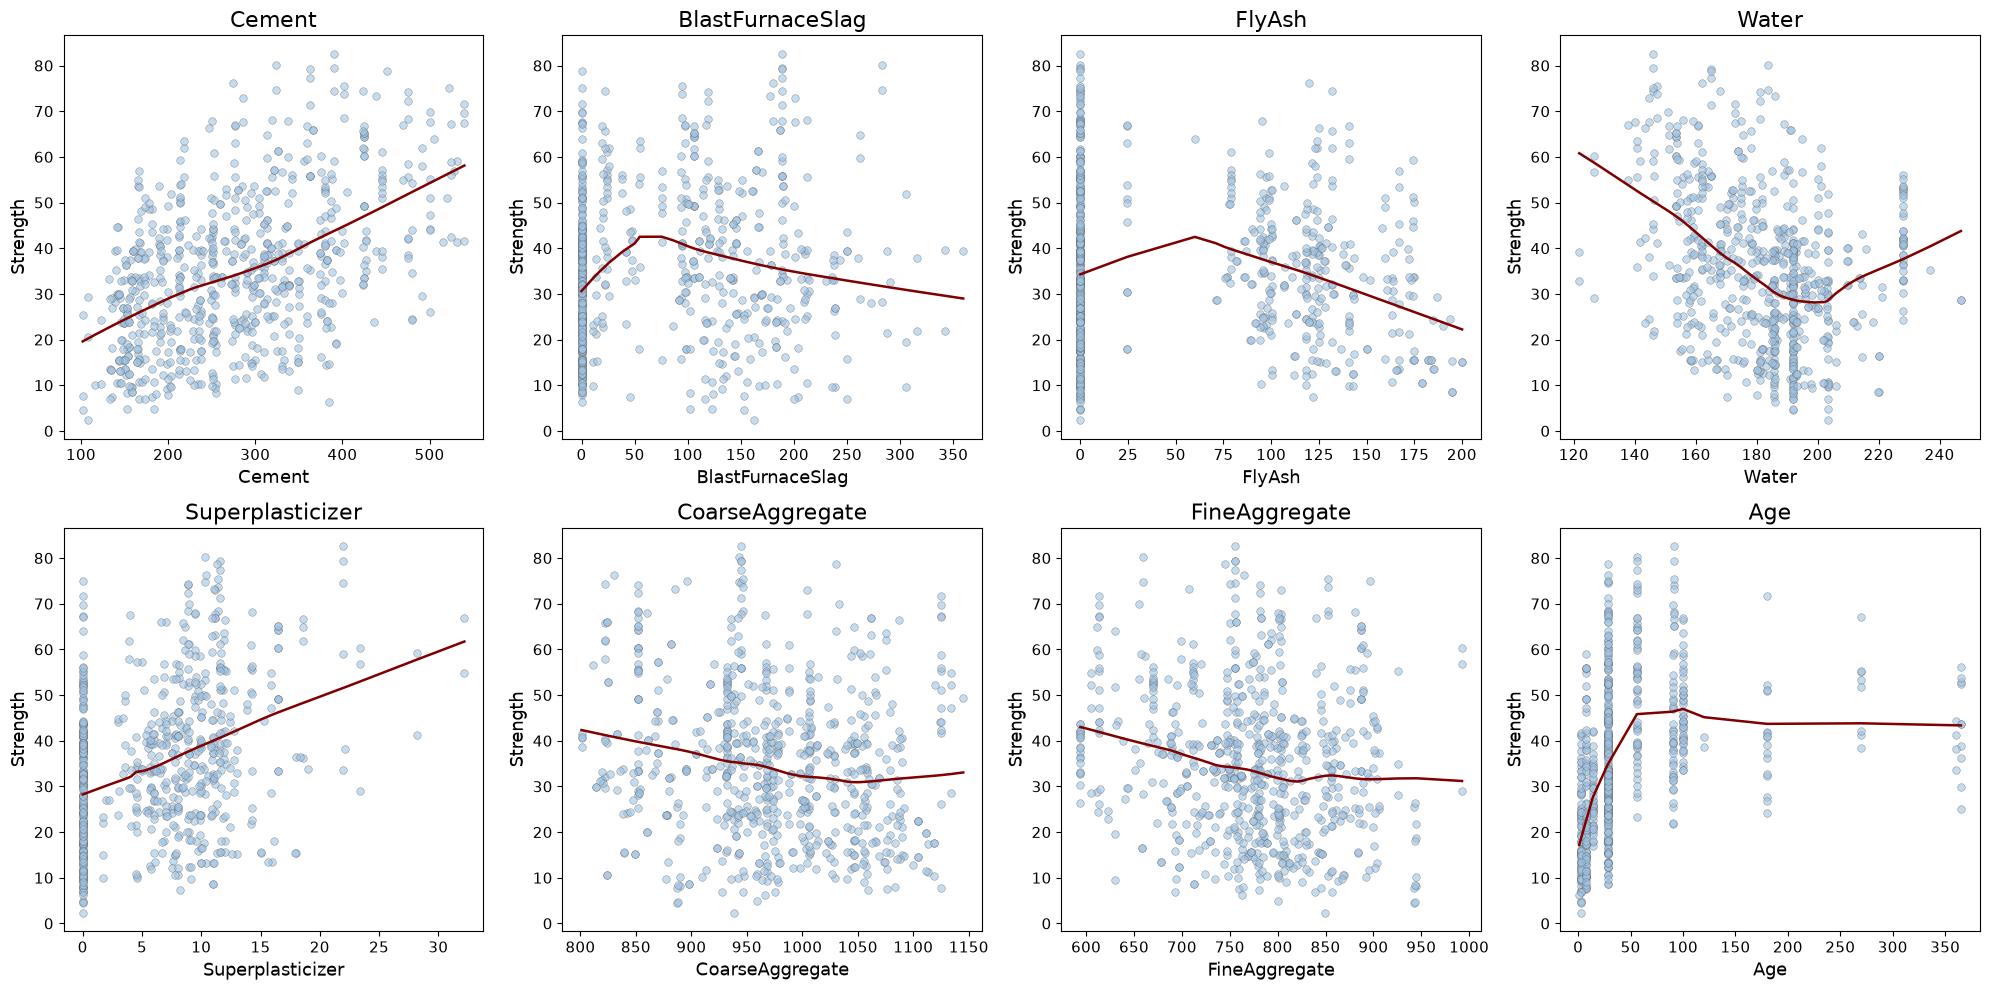

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for ax, variable in zip(axes.flat, predictores):
    dibujar_relacion(ax, datos[variable], datos["Strength"], variable)
    _ = ax.set_title(variable, fontsize=16)
    ax.xaxis.label.set_fontsize(13)
    ax.yaxis.label.set_fontsize(13)
    ax.tick_params(labelsize=11)
fig.tight_layout()
plt.show()

## Ajuste del modelo lineal simple

Primero predecimos `Strength` solo con `Cement`: $\widehat{y}=\widehat{\beta}_0+\widehat{\beta}_1\,\mathrm{Cement}$. `sm.add_constant` añade la columna de unos necesaria para estimar el intercepto; `sm.OLS(...).fit()` calcula los coeficientes por mínimos cuadrados. Con `missing="raise"` preferimos detenernos ante datos faltantes en vez de ignorar silenciosamente filas.

En el resumen, compara el signo y tamaño de la pendiente, su incertidumbre, el $R^2$ y el número de observaciones. La pendiente indica el cambio *promedio estimado* al añadir una unidad de cemento **en este modelo de una sola variable**: no aísla el efecto del cemento respecto a los demás componentes. El segundo gráfico superpone los datos y la recta predicha para ver dónde se aparta de la nube; se predice sobre una rejilla dentro del rango observado, sin extrapolar.

In [11]:
y = datos["Strength"]
X_simple = sm.add_constant(datos[["Cement"]], has_constant="add")
mod_lm0 = sm.OLS(y, X_simple, missing="raise").fit()
mod_lm0.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               Strength   R-squared:                       0.252
Model:                            OLS   Adj. R-squared:                  0.251
Method:                 Least Squares   F-statistic:                     237.4
Date:                Wed, 21 Oct 2026   Prob (F-statistic):           2.28e-46
Time:                        12:12:08   Log-Likelihood:                -2874.8
No. Observations:                 706   AIC:                             5754.
Df Residuals:                     704   BIC:                             5763.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         12.6200      1.561      8.086      0.000       9.556      15.684
Cement         0.0812      0.005     15.407      0.000       0.071       0.092
==============================================================================
Omnibus:                       14.989   Durbin-Watson:                   1.128
Prob(Omnibus):                  0.001   Jarque-Bera (JB):               14.055
Skew:                           0.299   Prob(JB):                     0.000887
Kurtosis:                       2.655   Cond. No.                         864.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

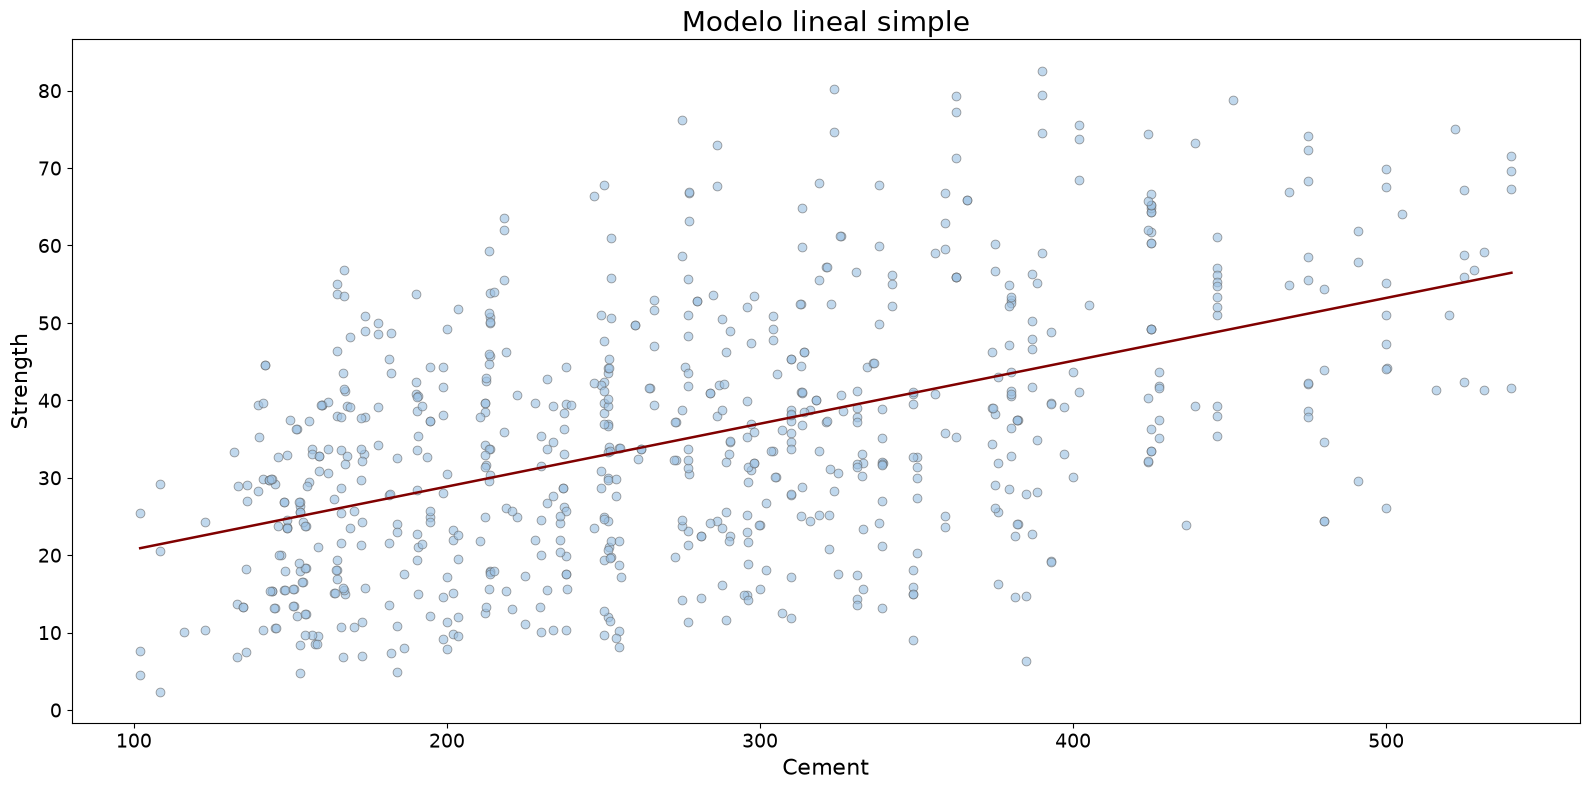

In [12]:
rejilla = pd.DataFrame({"Cement": np.linspace(datos["Cement"].min(), datos["Cement"].max(), 100)})
fig, ax = plt.subplots(figsize=(16, 8))
_ = ax.scatter(datos["Cement"], y, s=40, color="#9fc3e4", alpha=0.65,
               edgecolor="#666666", linewidth=0.6)
_ = ax.plot(rejilla["Cement"], mod_lm0.predict(sm.add_constant(rejilla, has_constant="add")),
            color="#800000", linewidth=1.8)
_ = ax.set(xlabel="Cement", ylabel="Strength", title="Modelo lineal simple")
fig.tight_layout()
plt.show()

## Ajuste del modelo multivariable

Incluimos las ocho predictoras reales y, **solo en `X_lineal`**, añadimos dos columnas de ruido artificial. El generador con semilla 42 reproduce exactamente los mismos valores al volver a ejecutar. No se añaden a `datos` ni a `predictores`, por lo que no aparecen después en los modelos polinómicos. `const` es el intercepto; `mod_lm1.params` muestra los coeficientes y `mod_lm1.summary()` añade errores estándar, contrastes e indicadores de ajuste.

Aquí cada coeficiente describe el cambio estimado en la respuesta al variar **una** predictora, manteniendo constantes las demás columnas del modelo. Si estas están relacionadas, la estimación puede volverse inestable. Añadir columnas no reduce el $R^2$ en **entrenamiento** por construcción, pero puede empeorar la predicción en datos nuevos. Los términos de ruido ilustran por qué un ajuste aparentemente mejor no basta para decidir qué conservar. Los p-valores dependen del modelo completo: interprétalos con cautela, no como criterio único de selección.

In [13]:
X_lineal = sm.add_constant(datos[predictores], has_constant="add")
azar = np.random.default_rng(42)
X_lineal["Ruido1"] = azar.normal(size=len(datos))
X_lineal["Ruido2"] = azar.normal(size=len(datos))
mod_lm1 = sm.OLS(y, X_lineal, missing="raise").fit()
mod_lm1.params

const              -33.448402
Cement               0.125191
BlastFurnaceSlag     0.106947
FlyAsh               0.091370
Water               -0.130094
Superplasticizer     0.347894
CoarseAggregate      0.021773
FineAggregate        0.021250
Age                  0.111899
Ruido1              -0.332507
Ruido2               0.288915
dtype: float64

In [14]:
mod_lm1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               Strength   R-squared:                       0.626
Model:                            OLS   Adj. R-squared:                  0.621
Method:                 Least Squares   F-statistic:                     116.3
Date:                Wed, 21 Oct 2026   Prob (F-statistic):          3.50e-141
Time:                        12:12:08   Log-Likelihood:                -2630.1
No. Observations:                 706   AIC:                             5282.
Df Residuals:                     695   BIC:                             5332.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const              -33.4484     33.395     -1.002      0.317     -99.015      32.118
Cement               0.1252      0.011     11.794      0.000       0.104       0.146
BlastFurnaceSlag     0.1069      0.012      8.559      0.000       0.082       0.131
FlyAsh               0.0914      0.015      5.915      0.000       0.061       0.122
Water               -0.1301      0.051     -2.555      0.011      -0.230      -0.030
Superplasticizer     0.3479      0.116      3.003      0.003       0.120       0.575
CoarseAggregate      0.0218      0.012      1.871      0.062      -0.001       0.045
FineAggregate        0.0213      0.013      1.608      0.108      -0.005       0.047
Age                  0.1119      0.006     17.533      0.000       0.099       0.124
Ruido1              -0.3325      0.389     -0.856      0.393      -1.096       0.430
Ruido2               0.2889      0.380      0.761      0.447      -0.456       1.034
==============================================================================
Omnibus:                        2.924   Durbin-Watson:                   1.391
Prob(Omnibus):                  0.232   Jarque-Bera (JB):                2.902
Skew:                          -0.157   Prob(JB):                        0.234
Kurtosis:                       2.985   Cond. No.                     1.13e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.13e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

**Microejercicio — selección manual (primer paso).** Ordena de mayor a menor los p-valores de las predictoras de `mod_lm1`, sin incluir la constante. ¿Qué variable revisarías primero para una posible eliminación? Compara después tu candidata con el primer paso de la selección por AIC. Un p-valor alto **no basta por sí solo para eliminarla**: también habría que comprobar cómo cambia el ajuste y si afecta a los coeficientes de las otras variables.

In [15]:
# Pista: usa mod_lm1.pvalues, quita "const" y ordena de mayor a menor.
# Tu línea de código:

## Selección de variables: eliminación hacia atrás con AIC

Partimos del modelo multivariable con ocho predictoras reales y dos de ruido. En cada iteración, la función **ajusta un modelo por cada término que se podría quitar** sin cambiar las filas ni la respuesta. Elige la retirada con el AIC menor y solo la acepta si mejora el AIC respecto al modelo actual; termina cuando ninguna retirada lo reduce. AIC combina calidad de ajuste y penalización por complejidad: **menor es mejor al comparar modelos de esta misma respuesta y muestra**.

La tabla `pasos_lineales` muestra el estado inicial (paso 0), qué término se eliminó en cada paso, el nuevo AIC y cuántos quedan. Mira qué ocurre con `Ruido1` y `Ruido2`: no se fuerza su eliminación solo por llamarse ruido. Los términos con varios coeficientes se tratan como una unidad, importante para los polinomios posteriores. El proceso es exploratorio y depende de la muestra; ni un AIC menor garantiza que se cumplan los supuestos ni los p-valores del modelo seleccionado incorporan la incertidumbre de la propia selección.

In [16]:
def seleccion_atras(respuesta, matriz, grupos):
    activas = list(grupos)

    def ajustar(variables):
        columnas = ["const"] + [columna for variable in variables for columna in grupos[variable]]
        return sm.OLS(respuesta, matriz[columnas], missing="raise").fit()

    with threadpool_limits(limits=1):
        modelo = ajustar(activas)
        pasos = [{"Paso": 0, "Eliminada": "—", "AIC": modelo.aic, "Términos": len(activas)}]
        while activas:
            candidatos = []
            for variable in activas:
                restantes = [nombre for nombre in activas if nombre != variable]
                candidato = ajustar(restantes)
                candidatos.append((candidato.aic, variable, candidato))
            aic, retirada, candidato = min(candidatos, key=lambda resultado: resultado[0])
            if aic >= modelo.aic - 1e-7:
                break
            activas.remove(retirada)
            modelo = candidato
            pasos.append({"Paso": len(pasos), "Eliminada": retirada, "AIC": aic, "Términos": len(activas)})
    return modelo, activas, pd.DataFrame(pasos)

In [17]:
grupos_lineales = {variable: [variable] for variable in X_lineal.columns if variable != "const"}
mod_lm2, seleccion_lineal, pasos_lineales = seleccion_atras(y, X_lineal, grupos_lineales)
pasos_lineales

,Paso,Eliminada,AIC,Términos
0,0,—,5282.286854,10
1,1,Ruido2,5280.874986,9
2,2,Ruido1,5279.638861,8


In [18]:
mod_lm2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               Strength   R-squared:                       0.625
Model:                            OLS   Adj. R-squared:                  0.621
Method:                 Least Squares   F-statistic:                     145.4
Date:                Wed, 21 Oct 2026   Prob (F-statistic):          4.65e-143
Time:                        12:12:08   Log-Likelihood:                -2630.8
No. Observations:                 706   AIC:                             5280.
Df Residuals:                     697   BIC:                             5321.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const              -32.9015     33.370     -0.986      0.324     -98.419      32.616
Cement               0.1254      0.011     11.818      0.000       0.105       0.146
BlastFurnaceSlag     0.1071      0.012      8.573      0.000       0.083       0.132
FlyAsh               0.0915      0.015      5.927      0.000       0.061       0.122
Water               -0.1314      0.051     -2.583      0.010      -0.231      -0.032
Superplasticizer     0.3455      0.116      2.985      0.003       0.118       0.573
CoarseAggregate      0.0214      0.012      1.840      0.066      -0.001       0.044
FineAggregate        0.0213      0.013      1.611      0.108      -0.005       0.047
Age                  0.1120      0.006     17.562      0.000       0.099       0.125
==============================================================================
Omnibus:                        3.041   Durbin-Watson:                   1.391
Prob(Omnibus):                  0.219   Jarque-Bera (JB):                3.029
Skew:                          -0.160   Prob(JB):                        0.220
Kurtosis:                       2.979   Cond. No.                     1.13e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.13e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

## Validación del modelo lineal

Antes de confiar en `mod_lm2`, inspeccionamos cuatro vistas de los residuos $e_i=y_i-\widehat y_i$:

1. **Residuos frente a ajustados:** idealmente, una banda sin curva clara alrededor de cero; una tendencia de LOWESS sugiere forma funcional insuficiente.
2. **Gráfico Q–Q:** compara los cuantiles de los residuos estandarizados con una distribución normal. Desviaciones, sobre todo en las colas, invitan a revisar la aproximación de normalidad.
3. **Escala y localización:** representa $\sqrt{|e_i^*|}$ frente al valor ajustado. Si la dispersión crece o decrece, la variabilidad podría no ser constante.
4. **Residuos frente a apalancamiento:** a la derecha están los casos con combinaciones de predictoras poco habituales; las líneas de Cook (0,5 y 1) orientan la búsqueda de casos que pueden modificar el ajuste.

**No son pruebas automáticas de validez.** Un punto fuera de lo habitual necesita inspección contextual; la independencia de los errores se aborda aparte y no puede inferirse de estos paneles.

In [19]:
def diagnosticos(modelo, titulo):
    influencia = modelo.get_influence()
    ajustados = np.asarray(modelo.fittedvalues)
    residuos = np.asarray(modelo.resid)
    estandarizados = influencia.resid_studentized_internal
    leverage = influencia.hat_matrix_diag
    fig, axes = plt.subplots(2, 2, figsize=(18, 11))

    axes[0, 0].scatter(ajustados, residuos, s=30, color="#9fc3e4",
                       edgecolor="#666666", linewidth=0.4, alpha=0.65)
    curva = lowess(residuos, ajustados, frac=2/3, it=3)
    axes[0, 0].plot(curva[:, 0], curva[:, 1], color="#800000", linewidth=1.8)
    axes[0, 0].axhline(0, color="#666666", linestyle="--")
    axes[0, 0].set(title="Residuos frente a ajustados", xlabel="Ajustados", ylabel="Residuos")

    sm.ProbPlot(estandarizados).qqplot(line="45", ax=axes[0, 1], marker="o", markersize=4, alpha=0.65)
    for linea in axes[0, 1].lines:
        if linea.get_marker() == "o":
            linea.set(markerfacecolor="#9fc3e4", markeredgecolor="#666666", markeredgewidth=0.6)
        else:
            linea.set(color="#800000", linewidth=1.8)
    axes[0, 1].set(title="Q–Q de residuos estandarizados", xlabel="Cuantiles normales",
                   ylabel="Residuos estandarizados")

    escala = np.sqrt(np.abs(estandarizados))
    axes[1, 0].scatter(ajustados, escala, s=30, color="#9fc3e4",
                       edgecolor="#666666", linewidth=0.4, alpha=0.65)
    curva = lowess(escala, ajustados, frac=2/3, it=3)
    axes[1, 0].plot(curva[:, 0], curva[:, 1], color="#800000", linewidth=1.8)
    axes[1, 0].set(title="Escala y localización", xlabel="Ajustados",
                   ylabel="Raíz de |residuo estandarizado|")

    axes[1, 1].scatter(leverage, estandarizados, s=30, color="#9fc3e4",
                       edgecolor="#666666", linewidth=0.4, alpha=0.65)
    axes[1, 1].axhline(0, color="#666666", linestyle="--")
    h = np.linspace(max(leverage.min(), 1e-5), leverage.max() * 1.05, 200)
    for distancia in [0.5, 1]:
        limite = np.sqrt(distancia * len(modelo.params) * (1 - h) / h)
        axes[1, 1].plot(h, limite, "--", color="#800000", alpha=0.65, label=f"Cook = {distancia}")
        axes[1, 1].plot(h, -limite, "--", color="#800000", alpha=0.65)
    axes[1, 1].set(title="Residuos y apalancamiento", xlabel="Apalancamiento",
                   ylabel="Residuo estandarizado",
                   ylim=(estandarizados.min() - 1, estandarizados.max() + 1))
    axes[1, 1].legend(fontsize=10)
    for eje in axes.flat:
        eje.title.set_fontsize(18)
        eje.xaxis.label.set_fontsize(16)
        eje.yaxis.label.set_fontsize(16)
        eje.tick_params(labelsize=14)
    fig.suptitle(titulo, fontsize=20)
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()

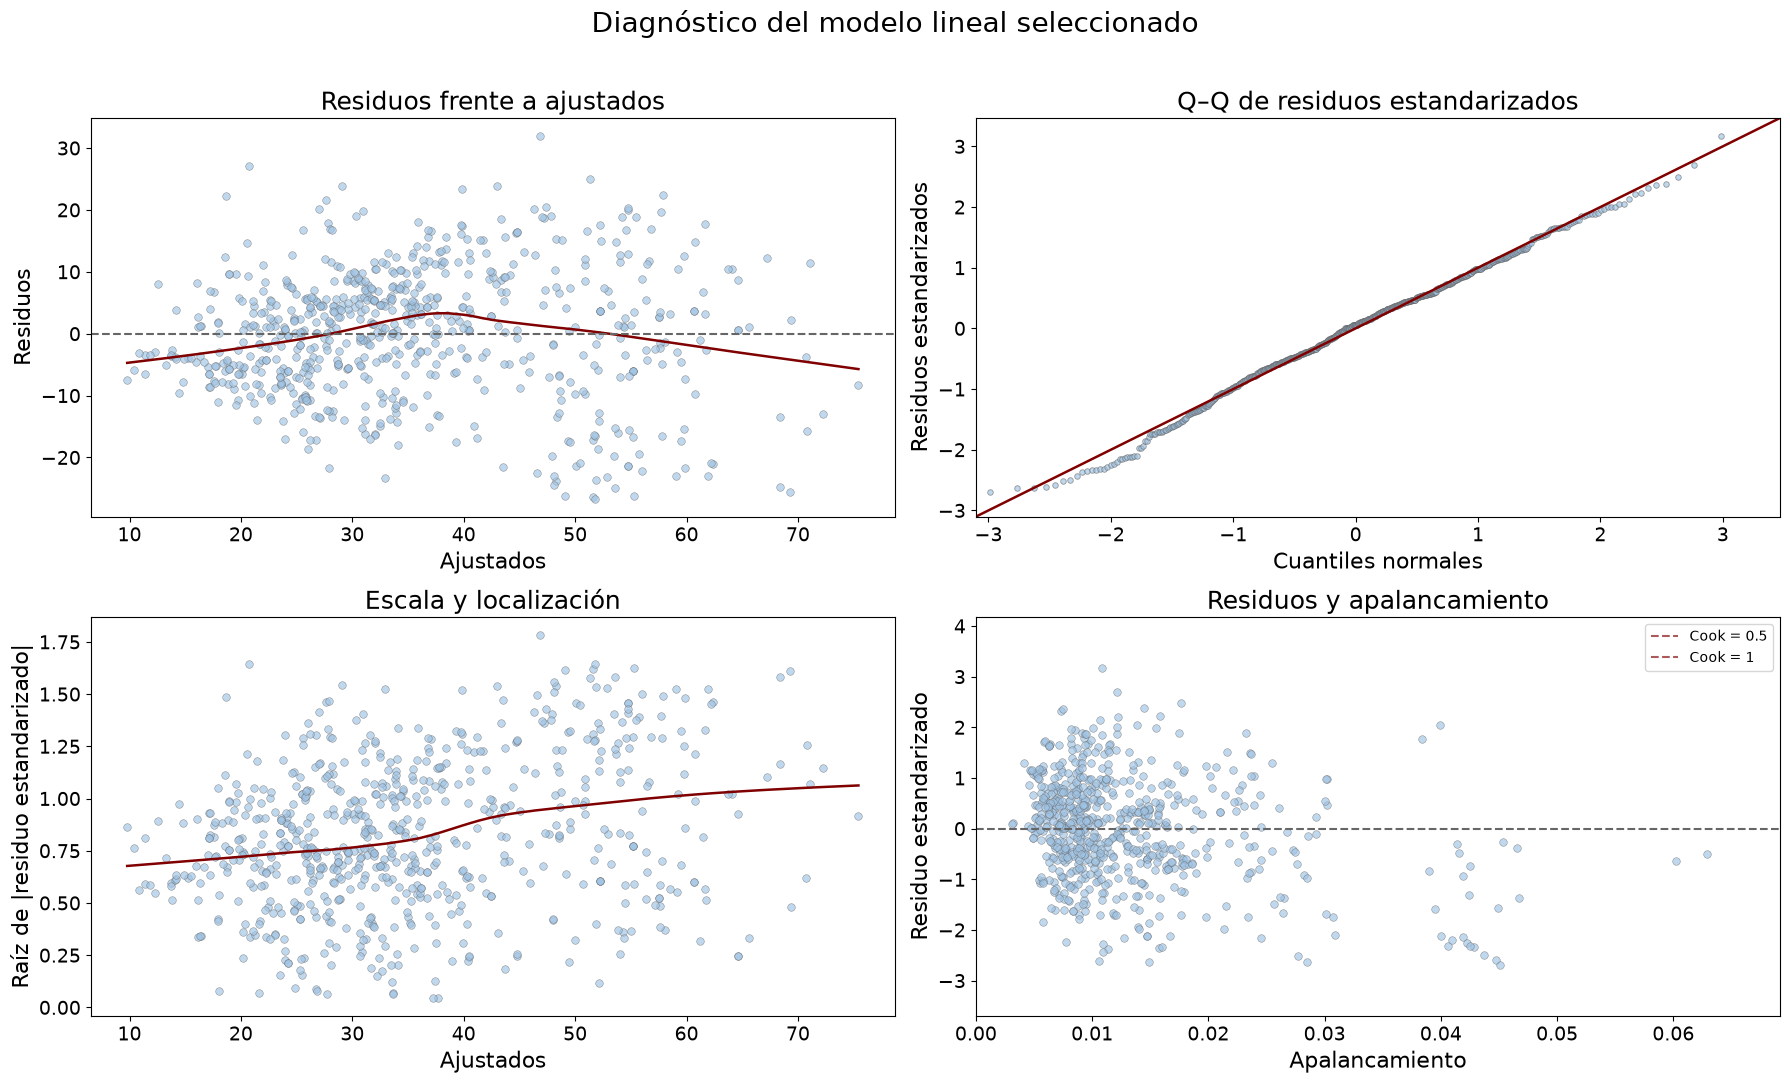

In [20]:
diagnosticos(mod_lm2, "Diagnóstico del modelo lineal seleccionado")

### Independencia de los errores

Dibujamos los residuos en el **orden de las filas del archivo de entrenamiento**. Una racha larga del mismo signo, una tendencia o un ciclo podrían señalar estructura que el modelo no recoge. La línea horizontal a cero facilita comparar signos y amplitudes.

**Límite importante:** el índice que hemos asignado no garantiza orden cronológico ni espacial. Si las filas se mezclaron antes de recibirlas, este gráfico no permite comprobar dependencia temporal; tampoco la ausencia de un patrón visible demuestra independencia. Para estudiarla rigurosamente harían falta datos sobre el muestreo y, si procede, el orden real de observación.

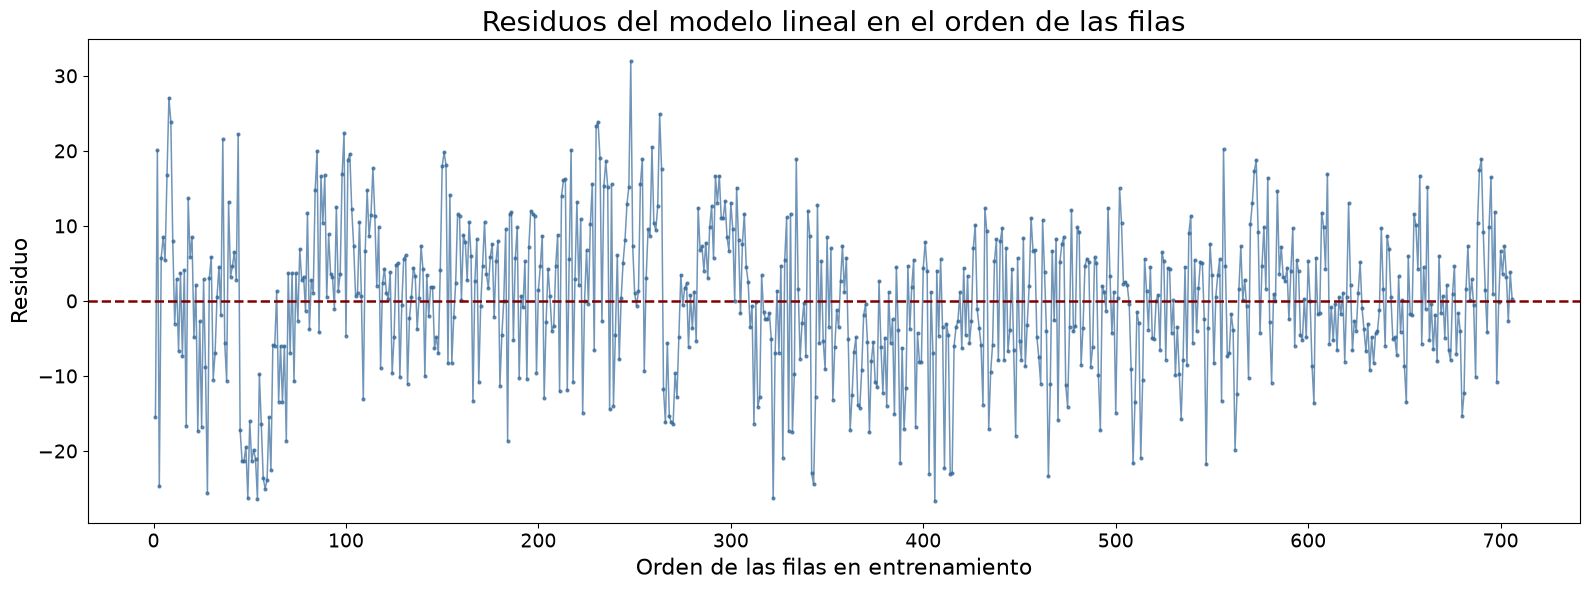

In [21]:
def grafico_orden_residuos(modelo, titulo):
    fig, ax = plt.subplots(figsize=(16, 6))
    orden = np.arange(1, len(modelo.resid) + 1)
    _ = ax.plot(orden, modelo.resid, color="#34699a", alpha=0.7, linewidth=1.1,
                marker=".", markersize=4)
    _ = ax.axhline(0, color="#800000", linestyle="--", linewidth=1.8)
    _ = ax.set(xlabel="Orden de las filas en entrenamiento", ylabel="Residuo", title=titulo)
    fig.tight_layout()
    plt.show()

grafico_orden_residuos(mod_lm2, "Residuos del modelo lineal en el orden de las filas")

**Microejercicio — residuos extremos.** Identifica en una sola línea de código las tres observaciones con mayor residuo en valor absoluto de `mod_lm2`. ¿Por qué conviene examinarlas antes de decidir si son errores?

In [22]:
# Pista: trabaja con los residuos del modelo seleccionado; usa valores absolutos y quédate con los tres mayores.
# Tu línea de código:

## Nueva descriptiva: lo que aún no explica el modelo

### Residuos frente a las variables predictoras

Ahora repetimos los gráficos exploratorios con los **residuos del modelo seleccionado** en el eje vertical, no con `Strength`. Si el modelo recogiera adecuadamente la relación con cada predictor, los residuos no deberían mostrar una curva persistente alrededor de la línea horizontal de cero. LOWESS ayuda a ver tendencias difíciles de apreciar en una nube densa.

Un patrón aquí puede indicar curvatura omitida, un grupo distinto o una transformación necesaria. **No significa necesariamente causalidad** ni justifica modificar a ciegas el modelo: conviene verificar si hay valores extremos, correlación entre predictoras y estabilidad de la tendencia. Compararemos estas gráficas con las del modelo polinómico.

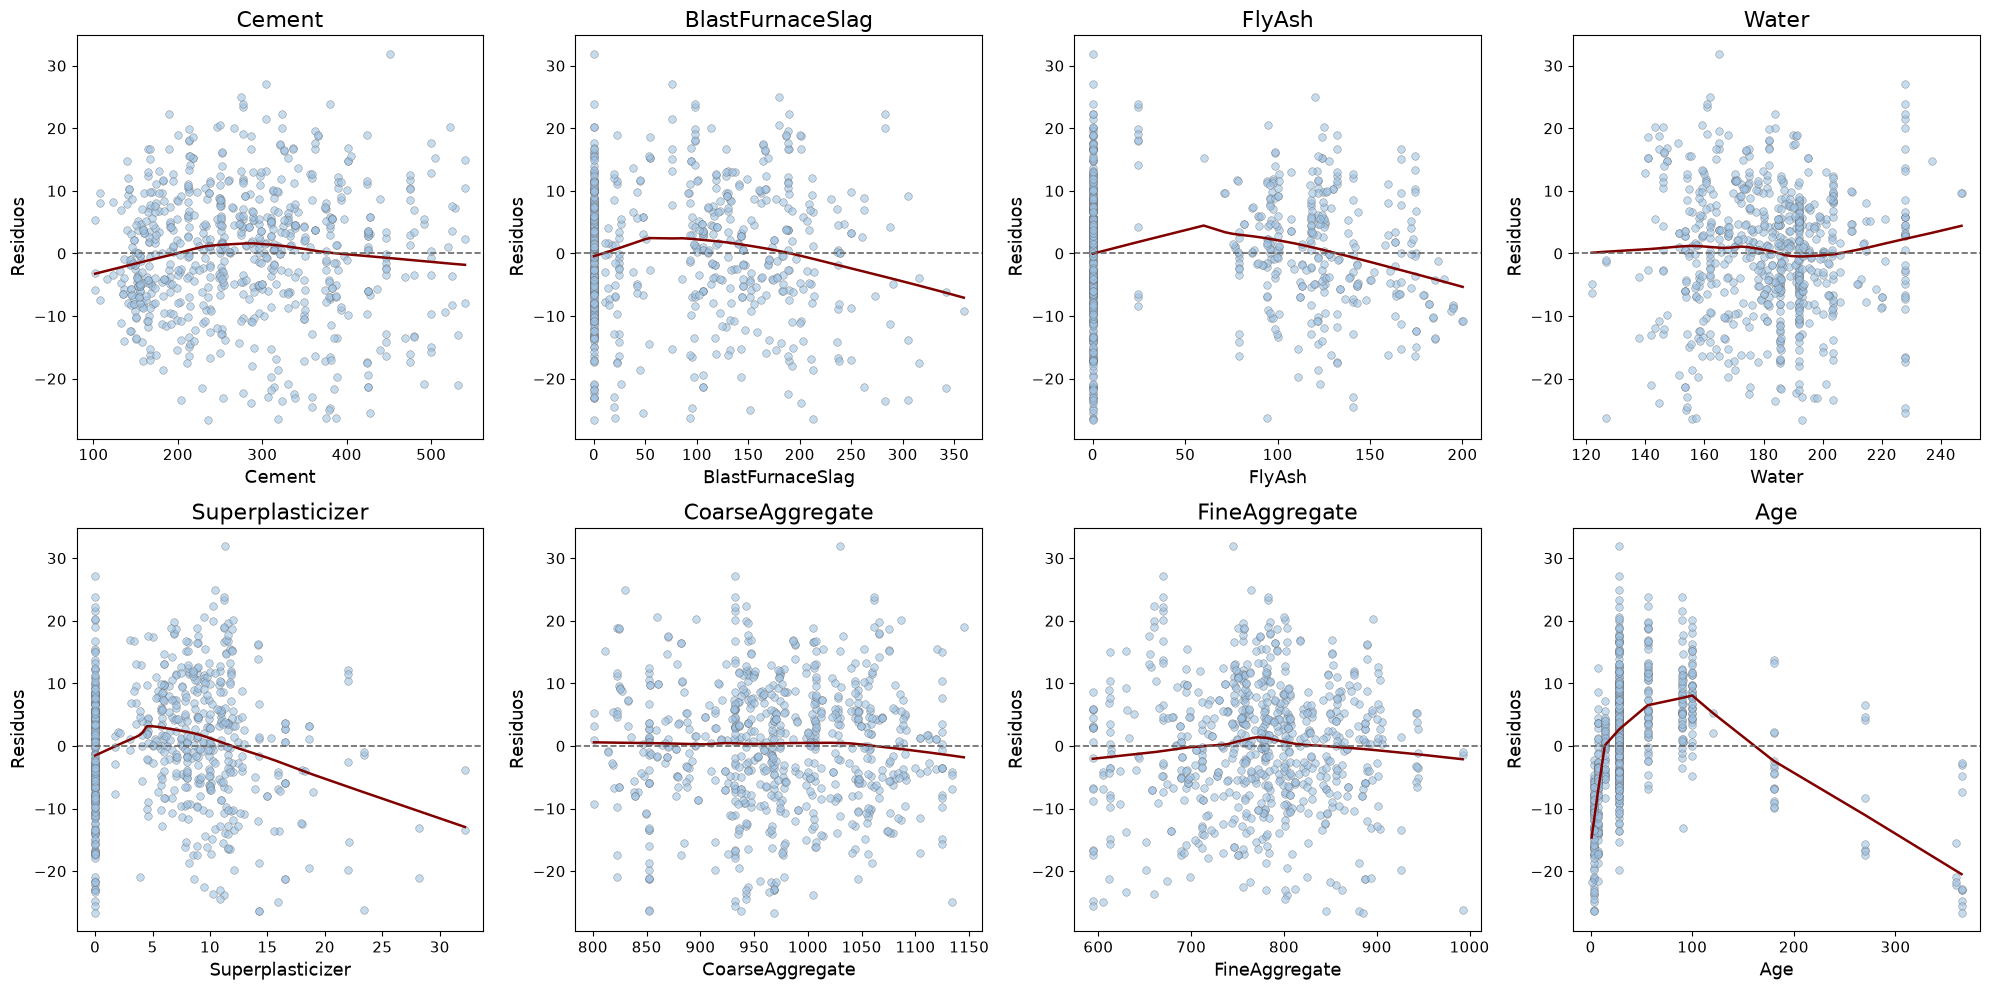

In [23]:
def residuos_predictoras(modelo, tabla, variables):
    fig, axes = plt.subplots(2, 4, figsize=(20, 10))
    for ax, variable in zip(axes.flat, variables):
        dibujar_relacion(ax, tabla[variable], modelo.resid, variable)
        ax.set(title=variable, ylabel="Residuos")
        ax.axhline(0, color="#666666", linestyle="--", linewidth=1.2)
    for ax in list(axes.flat)[len(variables):]:
        ax.set_visible(False)
    for ax in axes.flat:
        if ax.get_visible():
            ax.title.set_fontsize(16)
            ax.xaxis.label.set_fontsize(13)
            ax.yaxis.label.set_fontsize(13)
            ax.tick_params(labelsize=11)
    fig.tight_layout()
    plt.show()

residuos_predictoras(mod_lm2, datos, predictores)

### Gráficos de residuos y pruebas de curvatura

La función devuelve **gráficos y una tabla de pruebas F**. Para cada término que solo tiene coeficiente lineal, añade provisionalmente su cuadrado al modelo *ya ajustado* y comprueba si esa ampliación reduce el error de ajuste lo suficiente frente al modelo original. También añade el cuadrado del valor ajustado: esta última prueba es el **test de no aditividad de Tukey**, que busca una curvatura global no recogida por la forma actual.

Los términos que ya tienen grado 2 se dibujan, pero **no se vuelven a probar añadiendo el mismo cuadrado**. En la tabla, un p-valor pequeño señala evidencia contra la forma considerada en esa comparación, no identifica por sí solo la mejor transformación. Como miramos varias variables y pruebas, evita leer cada p-valor aislado como una decisión definitiva; comprueba también los gráficos y el sentido de la modificación.

In [24]:
def residuos_por_termino(modelo, tabla, grupos):
    variables = list(grupos)
    paneles = [(variable, tabla[variable], len(grupos[variable]) == 1) for variable in variables]
    paneles.append(("Ajustados (Tukey)", modelo.fittedvalues, True))
    filas = int(np.ceil(len(paneles) / 3))
    fig, axes = plt.subplots(filas, 3, figsize=(18, 4.5 * filas), squeeze=False)
    resultados = []
    for ax, (nombre, valores, probar) in zip(axes.flat, paneles):
        dibujar_relacion(ax, valores, modelo.resid, nombre)
        ax.set(title=nombre, ylabel="Residuos")
        ax.axhline(0, color="#666666", linestyle="--", linewidth=1.2)
        ax.title.set_fontsize(18)
        ax.xaxis.label.set_fontsize(14)
        ax.yaxis.label.set_fontsize(14)
        ax.tick_params(labelsize=12)
        if probar:
            x = np.asarray(valores, dtype=float)
            x = (x - x.mean()) / x.std()
            ampliada = np.column_stack([modelo.model.exog, x ** 2])
            ampliado = sm.OLS(modelo.model.endog, ampliada).fit()
            f, p, gl = ampliado.compare_f_test(modelo)
            resultados.append({"Término": nombre, "F": f, "p-valor": p})
    for ax in list(axes.flat)[len(paneles):]:
        ax.set_visible(False)
    fig.tight_layout()
    plt.show()
    return pd.DataFrame(resultados).set_index("Término")

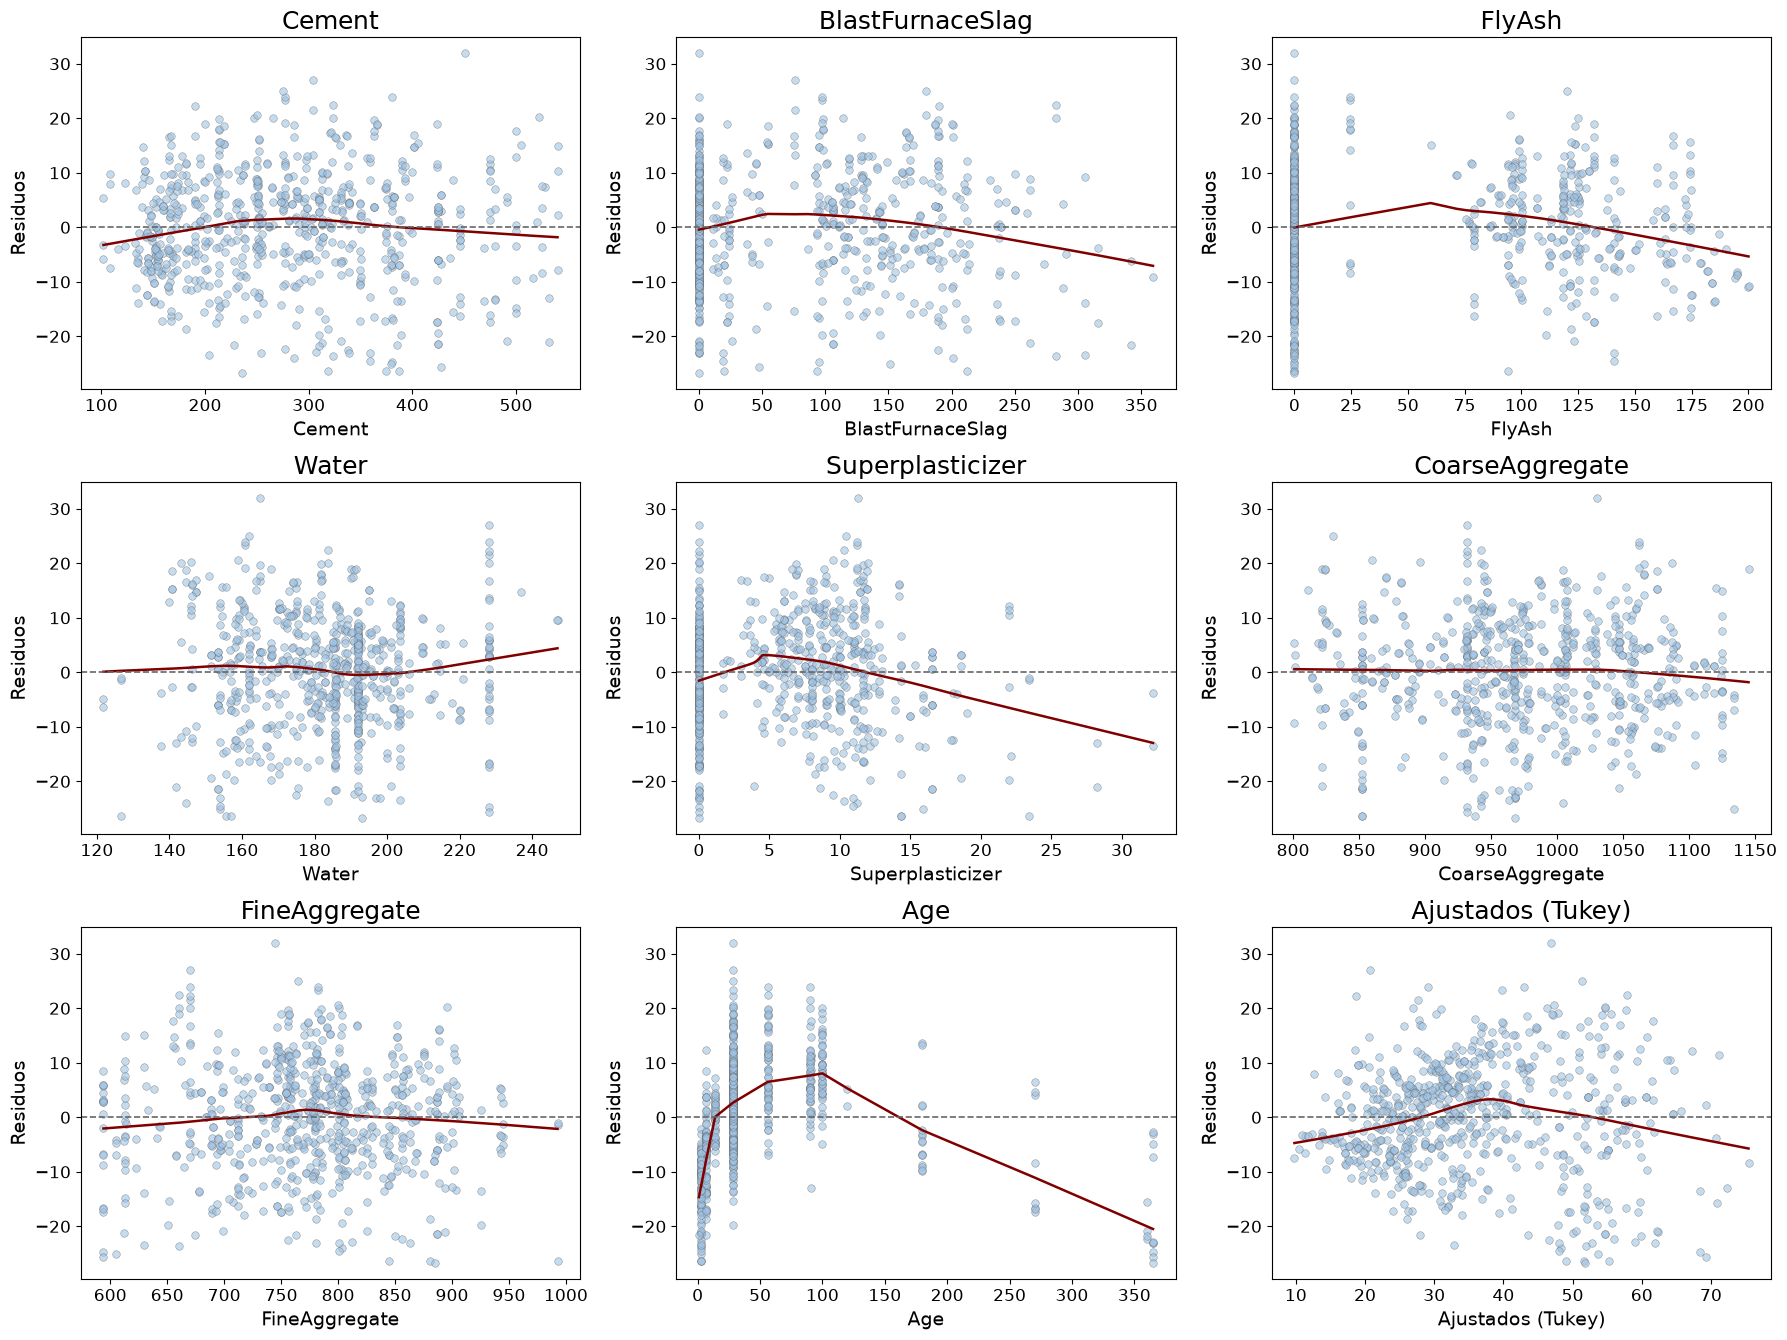

,F,p-valor
Término,,
Cement,4.601288,3.229339e-02
BlastFurnaceSlag,15.471918,9.213076e-05
FlyAsh,19.444131,1.199708e-05
Water,1.743339,1.871504e-01
Superplasticizer,41.749306,1.950030e-10
CoarseAggregate,0.016351,8.982890e-01
FineAggregate,12.064910,5.456079e-04
Age,324.970416,6.594440e-60
Ajustados (Tukey),30.319365,5.158442e-08


In [25]:
residuos_por_termino(mod_lm2, datos, {v: grupos_lineales[v] for v in seleccion_lineal})

## Transformaciones polinómicas de las predictoras

Permitimos curvatura de grado 2 para `Cement`, `BlastFurnaceSlag`, `FlyAsh`, `Water`, `Superplasticizer`, `FineAggregate` y `Age`; `CoarseAggregate` permanece lineal. En lugar de elevar directamente $x$ al cuadrado, calculamos $z=(x-\bar x_{\mathrm{train}})/s_{\mathrm{train}}$ y creamos las columnas $z$ y $z^2$. Centrar y escalar ayuda a la estabilidad numérica y modifica la interpretación individual de los coeficientes, **no** el conjunto de curvas cuadráticas que puede representar el modelo completo.

`diseno_polinomico(datos)` aprende medias y escalas **solo con entrenamiento** y las guarda. Cuando lleguemos al test, pasaremos esos mismos parámetros: usar su propia media filtraría información del test al preprocesamiento y haría incoherentes las columnas del modelo. `grupos_polinomicos` vincula las dos columnas de cada variable para conservarlas o retirarlas juntas.

Primero ajustamos `mod_lm4` con todos los términos y luego aplicamos la misma eliminación por AIC para obtener `mod_lm5`. Lee `pasos_polinomicos` para seguir cada retirada y el resumen posterior para comprobar el modelo resultante. La inclusión de $z^2$ describe curvatura **manteniendo las otras columnas del modelo constantes**; no implica extrapolación fiable fuera de los rangos vistos.

In [26]:
def diseno_polinomico(tabla, parametros=None):
    # Aprender medias y escalas solo al ajustar; reutilizarlas para predecir.
    if parametros is None:
        parametros = {v: (tabla[v].mean(), tabla[v].std(ddof=0))
                      for v in predictores if v != "CoarseAggregate"}
    matriz = pd.DataFrame({"const": 1.0}, index=tabla.index)
    for variable in predictores:
        if variable == "CoarseAggregate":
            matriz[variable] = tabla[variable]
        else:
            centro, escala = parametros[variable]
            z = (tabla[variable] - centro) / escala
            matriz[variable + "_1"] = z
            matriz[variable + "_2"] = z ** 2
    return matriz, parametros

In [27]:
X_polinomico, parametros_polinomicos = diseno_polinomico(datos)
grupos_polinomicos = {
    variable: [variable] if variable == "CoarseAggregate" else [variable + "_1", variable + "_2"]
    for variable in predictores
}
mod_lm4 = sm.OLS(y, X_polinomico).fit()
mod_lm4.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               Strength   R-squared:                       0.780
Model:                            OLS   Adj. R-squared:                  0.775
Method:                 Least Squares   F-statistic:                     162.9
Date:                Wed, 21 Oct 2026   Prob (F-statistic):          6.61e-215
Time:                        12:12:10   Log-Likelihood:                -2443.2
No. Observations:                 706   AIC:                             4918.
Df Residuals:                     690   BIC:                             4991.
Df Model:                          15                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 39.8720      9.201      4.333      0.000      21.806      57.938
Cement_1              11.3133      0.882     12.821      0.000       9.581      13.046
Cement_2              -0.2075      0.294     -0.707      0.480      -0.784       0.369
BlastFurnaceSlag_1     8.4931      0.929      9.137      0.000       6.668      10.318
BlastFurnaceSlag_2    -1.0535      0.332     -3.172      0.002      -1.705      -0.401
FlyAsh_1               3.7004      0.857      4.318      0.000       2.018       5.383
FlyAsh_2              -1.3600      0.513     -2.651      0.008      -2.367      -0.353
Water_1               -4.0420      0.840     -4.811      0.000      -5.692      -2.392
Water_2                0.9033      0.252      3.585      0.000       0.409       1.398
Superplasticizer_1     2.4370      0.629      3.874      0.000       1.202       3.672
Superplasticizer_2    -1.4595      0.249     -5.851      0.000      -1.949      -0.970
CoarseAggregate        0.0027      0.009      0.294      0.769      -0.016       0.021
FineAggregate_1        0.0729      0.848      0.086      0.931      -1.591       1.737
FineAggregate_2       -1.1602      0.252     -4.604      0.000      -1.655      -0.665
Age_1                 16.8120      0.608     27.671      0.000      15.619      18.005
Age_2                 -2.9989      0.158    -18.969      0.000      -3.309      -2.688
==============================================================================
Omnibus:                        7.922   Durbin-Watson:                   1.401
Prob(Omnibus):                  0.019   Jarque-Bera (JB):               11.575
Skew:                           0.024   Prob(JB):                      0.00307
Kurtosis:                       3.625   Cond. No.                     3.10e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 3.1e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [28]:
mod_lm5, seleccion_polinomica, pasos_polinomicos = seleccion_atras(y, X_polinomico, grupos_polinomicos)
pasos_polinomicos

,Paso,Eliminada,AIC,Términos
0,0,—,4918.346194,8
1,1,CoarseAggregate,4916.434809,7


In [29]:
mod_lm5.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               Strength   R-squared:                       0.780
Model:                            OLS   Adj. R-squared:                  0.775
Method:                 Least Squares   F-statistic:                     174.8
Date:                Wed, 21 Oct 2026   Prob (F-statistic):          5.13e-216
Time:                        12:12:10   Log-Likelihood:                -2443.2
No. Observations:                 706   AIC:                             4916.
Df Residuals:                     691   BIC:                             4985.
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 42.5715      0.724     58.804      0.000      41.150      43.993
Cement_1              11.1079      0.540     20.584      0.000      10.048      12.167
Cement_2              -0.2087      0.293     -0.711      0.477      -0.785       0.367
BlastFurnaceSlag_1     8.2761      0.566     14.626      0.000       7.165       9.387
BlastFurnaceSlag_2    -1.0406      0.329     -3.163      0.002      -1.687      -0.395
FlyAsh_1               3.5449      0.674      5.258      0.000       2.221       4.868
FlyAsh_2              -1.3868      0.505     -2.749      0.006      -2.377      -0.396
Water_1               -4.2486      0.462     -9.206      0.000      -5.155      -3.342
Water_2                0.8950      0.250      3.577      0.000       0.404       1.386
Superplasticizer_1     2.3836      0.602      3.961      0.000       1.202       3.565
Superplasticizer_2    -1.4588      0.249     -5.853      0.000      -1.948      -0.969
FineAggregate_1       -0.1411      0.435     -0.324      0.746      -0.995       0.713
FineAggregate_2       -1.1586      0.252     -4.602      0.000      -1.653      -0.664
Age_1                 16.8270      0.605     27.812      0.000      15.639      18.015
Age_2                 -3.0037      0.157    -19.112      0.000      -3.312      -2.695
==============================================================================
Omnibus:                        7.982   Durbin-Watson:                   1.401
Prob(Omnibus):                  0.018   Jarque-Bera (JB):               11.698
Skew:                           0.024   Prob(JB):                      0.00288
Kurtosis:                       3.629   Cond. No.                         15.0
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## Colinealidad de los términos seleccionados

Dos o más columnas pueden aportar información muy parecida. Aunque el modelo prediga razonablemente, esa **colinealidad** puede volver inestables los coeficientes y ampliar su incertidumbre; es una cuestión distinta de que los residuos muestren curvatura. `gvif` examina la correlación entre **coeficientes estimados** y excluye la constante.

Para términos de un coeficiente, `GVIF` coincide con el VIF habitual y un valor por encima de 5 sirve como **señal para revisar**, no como regla automática de eliminación. Un predictor cuadrático ocupa dos columnas, así que calculamos también `GVIF^(1/(2·Df))` para tener en cuenta los grados de libertad del término; no compares sin más su GVIF bruto con el VIF de un predictor de una sola columna. Revisa qué términos presentan más redundancia antes de interpretar signos y p-valores individuales.

In [30]:
def gvif(modelo, grupos):
    covarianza = modelo.cov_params().drop(index="const", columns="const")
    desviaciones = np.sqrt(np.diag(covarianza))
    correlacion = covarianza / np.outer(desviaciones, desviaciones)
    columnas = list(correlacion.columns)

    def logdet(matriz):
        if matriz.size == 0:
            return 0.0
        signo, valor = np.linalg.slogdet(matriz)
        if signo <= 0:
            raise ValueError("La matriz de coeficientes es singular.")
        return valor

    total = logdet(correlacion.to_numpy())
    resultados = []
    for variable, terminos in grupos.items():
        dentro = [columnas.index(termino) for termino in terminos]
        fuera = [i for i in range(len(columnas)) if i not in dentro]
        matriz = correlacion.to_numpy()
        valor = np.exp(logdet(matriz[np.ix_(dentro, dentro)]) + logdet(matriz[np.ix_(fuera, fuera)]) - total)
        gl = len(dentro)
        resultados.append({"Término": variable, "GVIF": valor, "Df": gl,
                           "GVIF^(1/(2·Df))": valor ** (1 / (2 * gl))})
    return pd.DataFrame(resultados).set_index("Término")

In [31]:
grupos_seleccionados = {variable: grupos_polinomicos[variable] for variable in seleccion_polinomica}
gvif(mod_lm5, grupos_seleccionados)

,GVIF,Df,GVIF^(1/(2·Df))
Término,,,
Cement,3.679321,2,1.384975
BlastFurnaceSlag,3.185465,2,1.335959
FlyAsh,4.867835,2,1.485368
Water,3.800342,2,1.396226
Superplasticizer,4.945473,2,1.491255
FineAggregate,3.009788,2,1.317146
Age,1.207466,2,1.048259


## Validación del modelo polinómico

Repetimos los cuatro diagnósticos y el gráfico de residuos en orden con `mod_lm5`: **la referencia es el modelo lineal seleccionado `mod_lm2`**, no solo el resumen numérico del polinómico. Pregunta: ¿desaparece alguna curvatura en residuos frente a ajustados?, ¿cambia la dispersión?, ¿siguen destacando casos en el Q–Q o el panel de Cook? La corrección de una pauta no implica que todas las hipótesis sean correctas.

La celda siguiente vuelve a trazar residuos frente a los términos conservados y sus posibles pruebas de curvatura. Como muchos ya incluyen $z$ y $z^2$, sus gráficos son más informativos que volver a añadir exactamente ese grado 2. El microejercicio posterior compara medianas de **errores absolutos en entrenamiento**: una medida menor describe estos datos, pero para valorar la capacidad predictiva reservamos el test de la parte final.

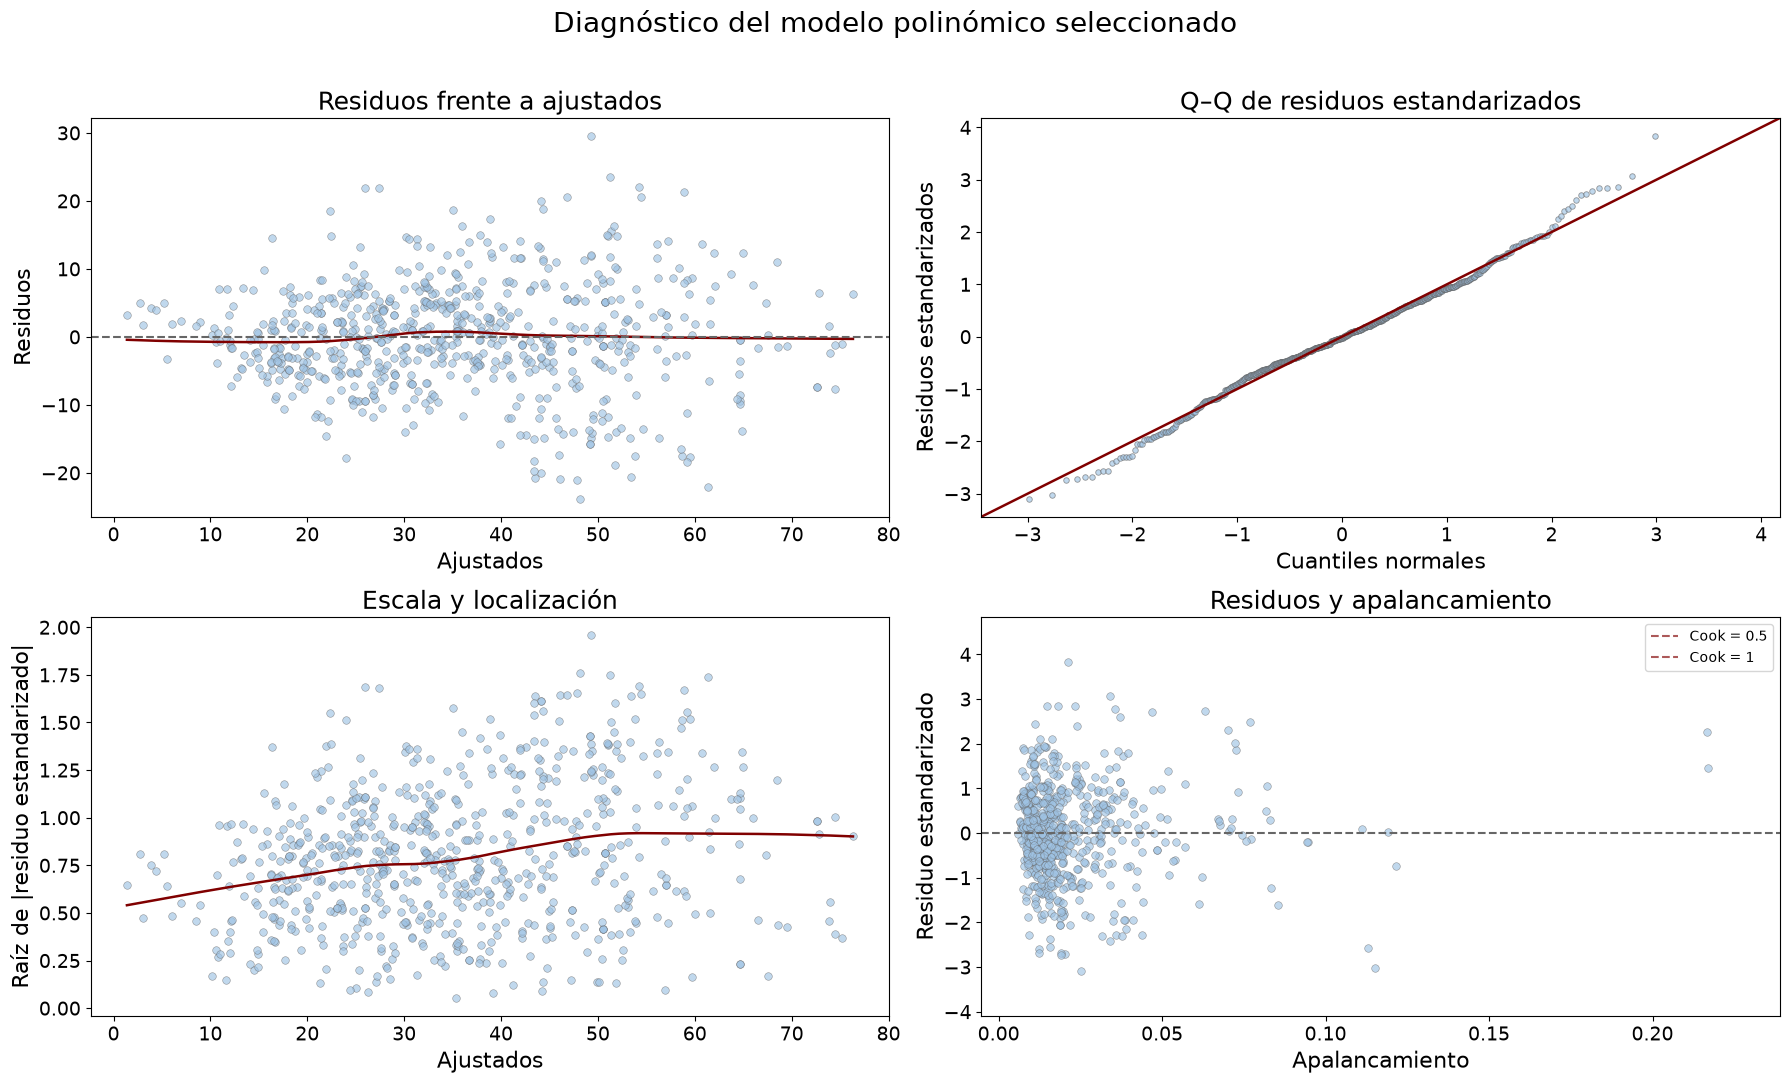

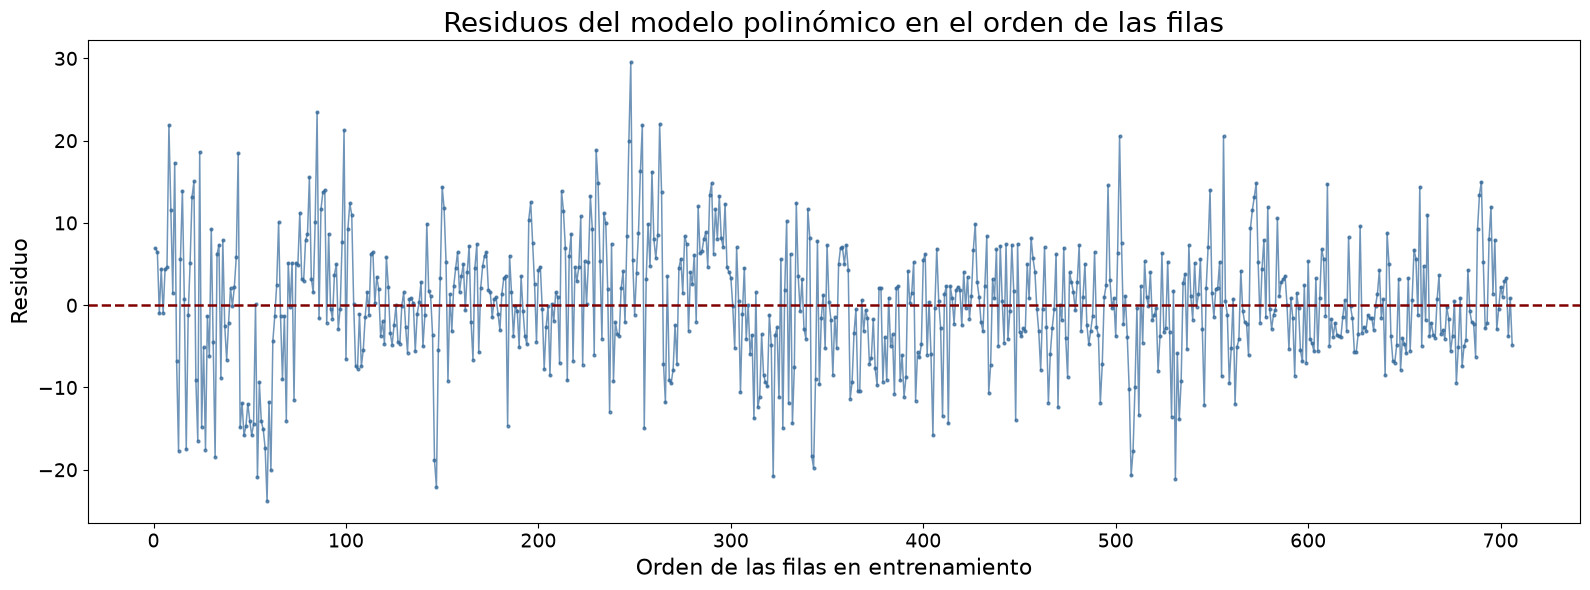

In [32]:
diagnosticos(mod_lm5, "Diagnóstico del modelo polinómico seleccionado")
grafico_orden_residuos(mod_lm5, "Residuos del modelo polinómico en el orden de las filas")

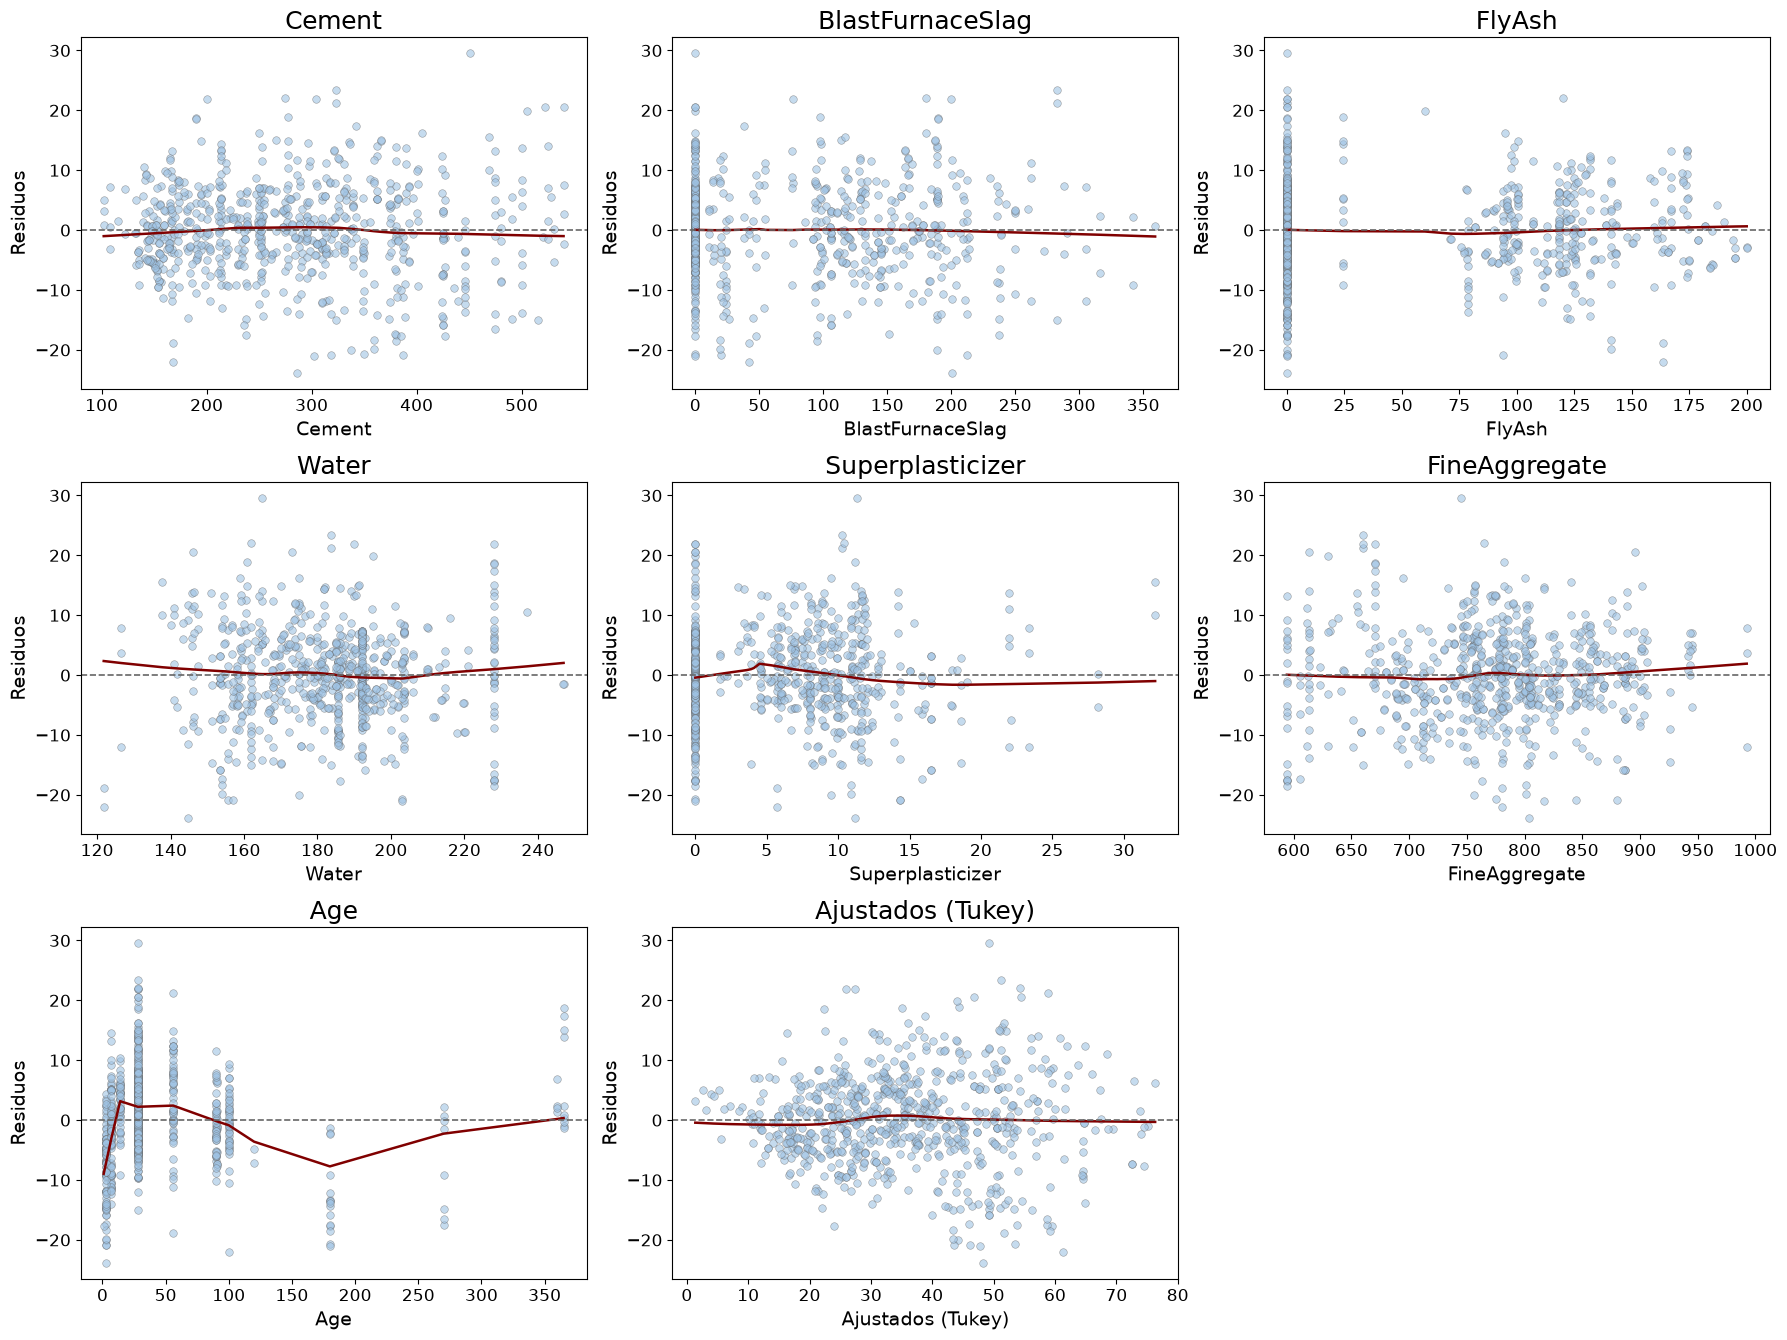

,F,p-valor
Término,,
Ajustados (Tukey),0.927492,0.335853


In [33]:
residuos_por_termino(mod_lm5, datos, grupos_seleccionados)

**Microejercicio — errores de ajuste.** Compara en una sola línea de código la mediana de los residuos **en valor absoluto** de `mod_lm2` y `mod_lm5`. ¿Cuál ajusta mejor estas observaciones? Recuerda que ambas medidas corresponden al entrenamiento, no al test.

In [34]:
# Pista: toma la mediana de los valores absolutos de los residuos de cada modelo.
# Tu línea de código:

## Transformación Box–Cox de la respuesta

Si la dispersión de los residuos depende del nivel de la respuesta o la normalidad de sus colas parece deficiente, podemos **explorar** una transformación de `Strength`. Box–Cox exige valores **estrictamente positivos** y define una familia de potencias indexadas por $\lambda$: $\lambda=1$ representa la escala original salvo un desplazamiento, y $\lambda=0$ corresponde al logaritmo (por continuidad de la definición estándar).

La función calcula, para cada $\lambda$, la verosimilitud del modelo que usa las predictoras de `mod_lm5`; incluye el término de cambio de escala (jacobiano), necesario para comparar potencias de la misma respuesta. `minimize_scalar` busca su máximo y `bc` guarda un perfil de valores para dibujarlo. La línea horizontal del gráfico marca un corte aproximado de verosimilitud para un intervalo del 95 %; mira si $\lambda=1$ queda cerca de las potencias plausibles.

**No confundas** este perfil exploratorio con demostrar que la transformación mejora la predicción. Después veremos los diagnósticos del modelo transformado; al cambiar la respuesta, sus coeficientes y su AIC no se comparan directamente con los del modelo en escala original.

In [35]:
def logverosimilitud_boxcox(valor_lambda, modelo):
    respuesta = np.asarray(modelo.model.endog, dtype=float)
    if (respuesta <= 0).any():
        raise ValueError("Box–Cox requiere una respuesta estrictamente positiva.")
    transformada = boxcox(respuesta, valor_lambda)
    coeficientes = modelo.model.pinv_wexog @ transformada
    residuos = transformada - modelo.model.exog @ coeficientes
    n = len(respuesta)
    return -n / 2 * np.log(np.sum(residuos ** 2) / n) + (valor_lambda - 1) * np.log(respuesta).sum()

optimo_lambda = minimize_scalar(lambda valor: -logverosimilitud_boxcox(valor, mod_lm5),
                                bracket=(-1, 1), method="brent")
if not optimo_lambda.success:
    raise RuntimeError("No se ha podido estimar lambda.")
lamb = optimo_lambda.x
bc = pd.DataFrame({"lambda": np.linspace(-2, 2, 201)})
bc["logLik"] = [logverosimilitud_boxcox(valor, mod_lm5) for valor in bc["lambda"]]
lamb

np.float64(0.657420538977791)

In [36]:
def explorar_boxcox(valor_lambda):
    fig, ax = plt.subplots(figsize=(16, 8))
    ax.plot(bc["lambda"], bc["logLik"], color="#34699a", linewidth=2)
    ax.axvline(lamb, color="#800000", linestyle="--", linewidth=1.8,
               label=f"Lambda estimada: {lamb:.3f}")
    ax.axvline(valor_lambda, color="#6f9fc8", linewidth=1.8,
               label=f"Lambda seleccionada: {valor_lambda:.2f}")
    corte = logverosimilitud_boxcox(lamb, mod_lm5) - stats.chi2.ppf(0.95, 1) / 2
    ax.axhline(corte, color="#666666", linestyle=":", linewidth=1.5,
               label="Corte del intervalo del 95 %")
    ax.set(xlabel="Lambda", ylabel="Log-verosimilitud", title="Perfil Box–Cox")
    ax.legend(fontsize=12)
    fig.tight_layout()
    plt.show()

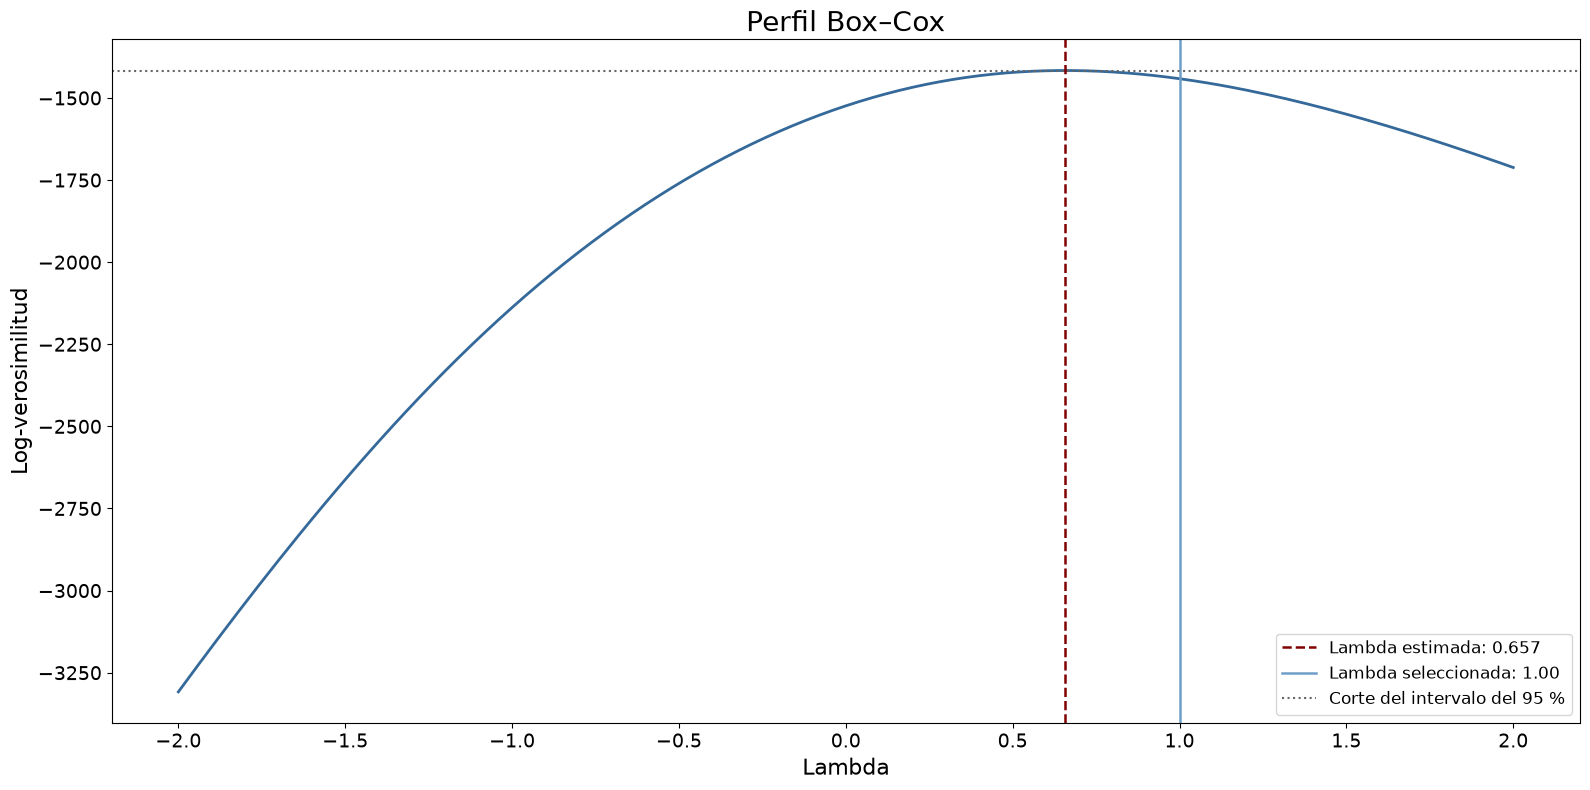

In [37]:
# Compara el perfil con la transformación identidad (lambda = 1).
explorar_boxcox(1.0)

### Ajustar un modelo con la respuesta transformada

Con la estimación `lamb` creamos `Strength2`. La función usa $\log(y)$ cuando $\lambda$ es prácticamente cero y, en otro caso, $y^\lambda$. Para un $\lambda$ fijo distinto de cero, esta potencia y la forma Box–Cox estándar $(y^\lambda-1)/\lambda$ difieren en un cambio afín; el perfil anterior sirve para escoger la potencia, mientras este modelo se ajusta con la forma concreta indicada en el código.

`mod_lm6` conserva los términos polinómicos de las otras predictoras, pero **excluye `CoarseAggregate`** en este ajuste ilustrativo. Su respuesta ahora es `Strength2`: un cambio unitario de una predictora modifica la *escala transformada*, no directamente los MPa originales. Por ello, los coeficientes, residuos y AIC de `mod_lm6` **no deben compararse como si la respuesta fuera idéntica** a la de `mod_lm5`. Esta rama no sustituye al modelo final de predicción en la escala original.

In [38]:
def transformar_respuesta(valores, valor_lambda):
    return np.log(valores) if abs(valor_lambda) < 1e-8 else np.power(valores, valor_lambda)

datos["Strength2"] = transformar_respuesta(datos["Strength"], lamb)
variables_sin_coarse = [variable for variable in predictores if variable != "CoarseAggregate"]
columnas_sin_coarse = ["const"] + [columna for variable in variables_sin_coarse
                                   for columna in grupos_polinomicos[variable]]
mod_lm6 = sm.OLS(datos["Strength2"], X_polinomico[columnas_sin_coarse]).fit()
mod_lm6.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              Strength2   R-squared:                       0.782
Model:                            OLS   Adj. R-squared:                  0.778
Method:                 Least Squares   F-statistic:                     177.3
Date:                Wed, 21 Oct 2026   Prob (F-statistic):          1.09e-217
Time:                        12:12:11   Log-Likelihood:                -1292.0
No. Observations:                 706   AIC:                             2614.
Df Residuals:                     691   BIC:                             2682.
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 11.7025      0.142     82.550      0.000      11.424      11.981
Cement_1               2.2093      0.106     20.907      0.000       2.002       2.417
Cement_2              -0.1008      0.057     -1.755      0.080      -0.214       0.012
BlastFurnaceSlag_1     1.6092      0.111     14.523      0.000       1.392       1.827
BlastFurnaceSlag_2    -0.1945      0.064     -3.019      0.003      -0.321      -0.068
FlyAsh_1               0.8052      0.132      6.100      0.000       0.546       1.064
FlyAsh_2              -0.3520      0.099     -3.563      0.000      -0.546      -0.158
Water_1               -0.8112      0.090     -8.976      0.000      -0.989      -0.634
Water_2                0.1693      0.049      3.455      0.001       0.073       0.266
Superplasticizer_1     0.4511      0.118      3.828      0.000       0.220       0.682
Superplasticizer_2    -0.2834      0.049     -5.807      0.000      -0.379      -0.188
FineAggregate_1       -0.0697      0.085     -0.819      0.413      -0.237       0.098
FineAggregate_2       -0.2163      0.049     -4.387      0.000      -0.313      -0.119
Age_1                  3.3715      0.118     28.458      0.000       3.139       3.604
Age_2                 -0.6009      0.031    -19.526      0.000      -0.661      -0.540
==============================================================================
Omnibus:                        1.982   Durbin-Watson:                   1.440
Prob(Omnibus):                  0.371   Jarque-Bera (JB):                1.810
Skew:                          -0.096   Prob(JB):                        0.405
Kurtosis:                       3.158   Cond. No.                         15.0
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## Validación del modelo con respuesta transformada

Aplicamos la misma función de cuatro paneles a `mod_lm6`. Busca si la curva de residuos frente a ajustados se acerca a cero, si la dispersión se hace más uniforme y si las colas del Q–Q siguen desviándose. La transformación podría mejorar un aspecto y no otro: **no basta con mirar un indicador**.

Ten presente que ahora el residuo es `Strength2` observada menos `Strength2` ajustada; la amplitud de sus ejes no está en las mismas unidades que los residuos de `mod_lm5`. Lo útil es comparar la **forma** de los patrones, no el tamaño numérico de los residuos sin volver a la escala original.

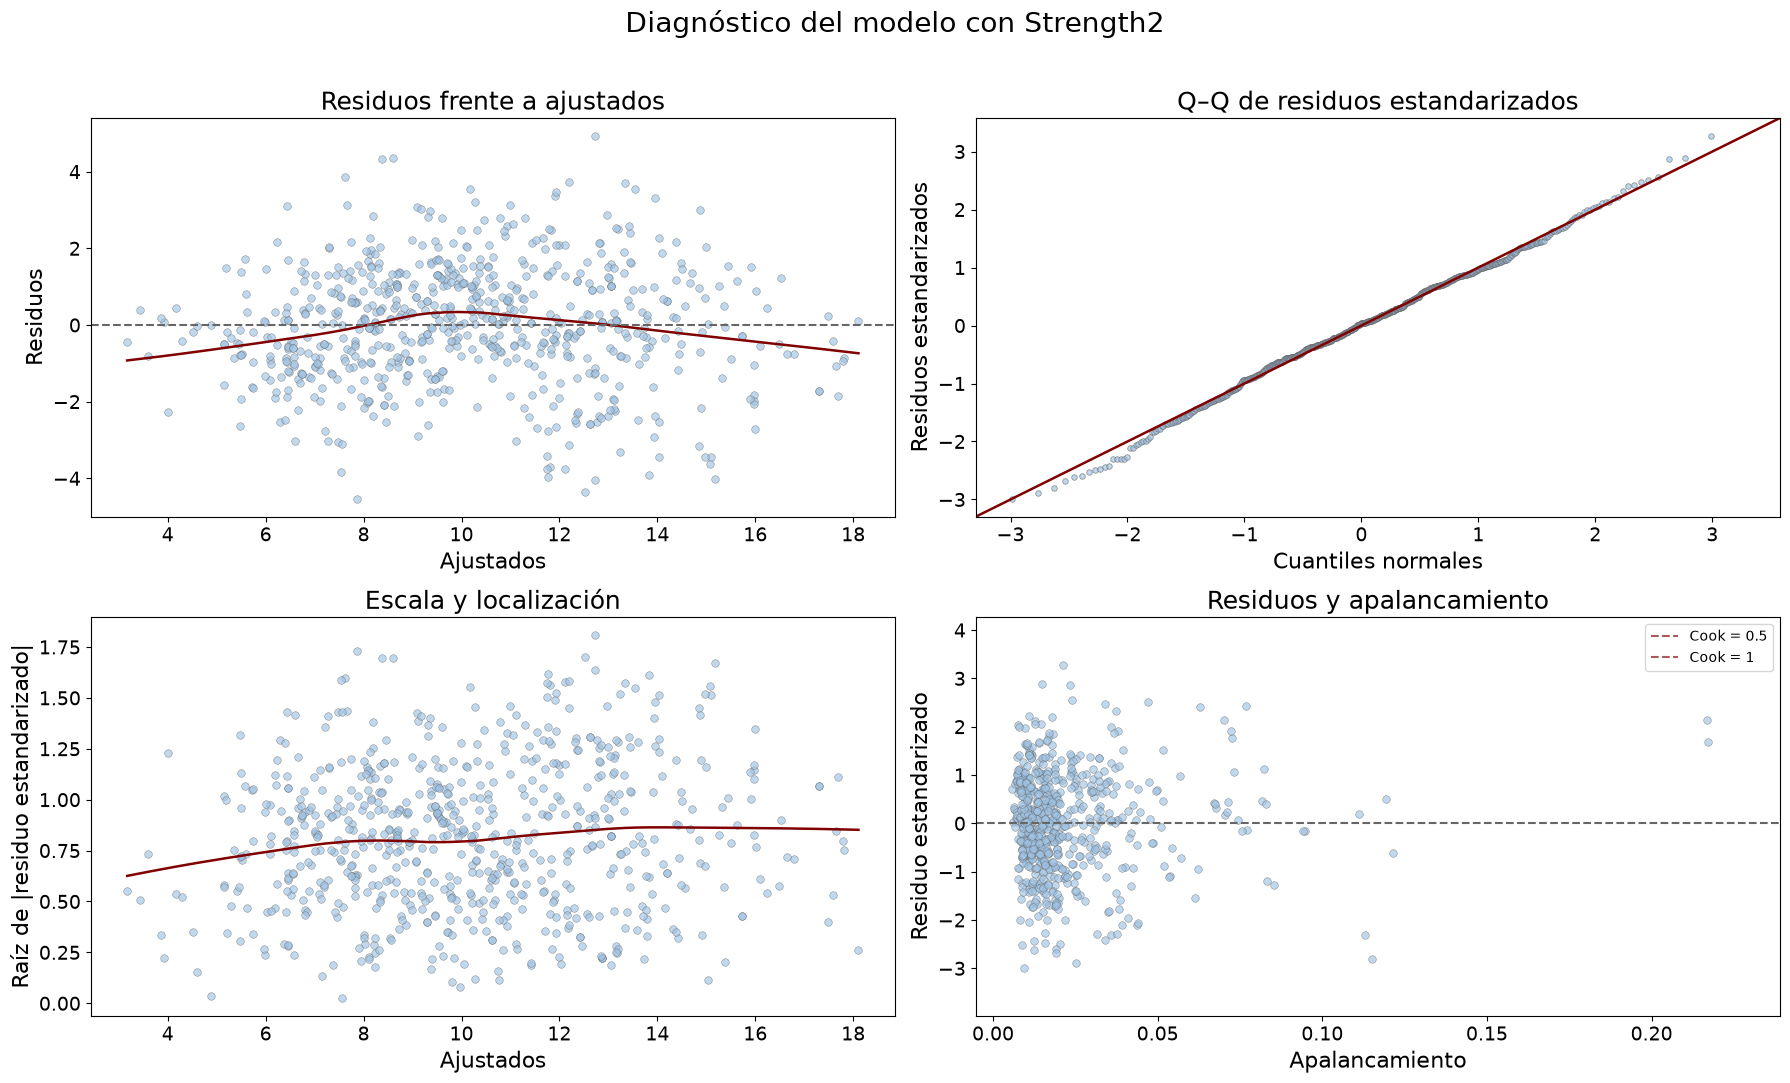

In [39]:
diagnosticos(mod_lm6, "Diagnóstico del modelo con Strength2")

### Ejercicio 3.1 — Transformar predictores con cuidado

Este ejercicio cambia **una predictora**, no la respuesta: mantenemos `Strength` para poder comparar modelos ajustados sobre **las mismas filas y la misma escala**. Trabaja sobre una copia y conserva `datos`, `X_lineal` y los modelos anteriores; las celdas posteriores los necesitan.

1. **Comprobar el dominio.** Examina los mínimos de las predictoras originales. $\log(x)$ solo está definido para $x>0$ en estos cálculos: detecta las columnas que contienen ceros y elige `Cement`, positiva en todo el entrenamiento. No uses `np.log` directamente sobre columnas con cero.
2. **Construir y ajustar.** Empieza por `X_lineal.copy()`, sustituye **solo** su columna `Cement` por `np.log` de los valores correspondientes y ajusta un nuevo `sm.OLS(y, ...)`. Compara su AIC con `mod_lm1.aic`: las filas y la respuesta son las mismas, de modo que esa comparación es pertinente. Un AIC más bajo sugiere una mejor combinación de ajuste y complejidad, no prueba que el modelo sea correcto.
3. **Diagnosticar.** Usa `diagnosticos(...)` con el nuevo ajuste y compáralo visualmente con el modelo lineal original: busca cambios en curvatura, dispersión, Q–Q e influencia. ¿La transformación mejora la pauta que te preocupaba o aparece otro problema?

Escribe cada apartado en su celda de pistas. No sustituyas `mod_lm5`: sigue siendo el modelo final que se usará para evaluar test.

In [40]:
# 3.1.1 — Comprobar el dominio de las transformaciones.
# Pista: consulta los mínimos de predictores; un valor cero impide usar np.log directamente.
# Tu código:

In [41]:
# 3.1.2 — Ajustar un modelo con el logaritmo de Cement.
# Pista: parte de X_lineal.copy(), modifica solo la copia y ajusta con sm.OLS(y, ...).
# Compara su AIC con mod_lm1.aic; no sobrescribas los modelos originales.
# Tu código:

In [42]:
# 3.1.3 — Diagnosticar el modelo alternativo.
# Pista: reutiliza diagnosticos(...) y contrasta los patrones con el modelo sin logaritmos.
# Tu código:

## Observaciones influyentes

Un **residuo grande** significa que una respuesta está lejos de la predicción; **apalancamiento alto** significa que la combinación de predictoras es inusual; **influencia alta** significa que una observación puede alterar bastante el modelo ajustado. No son sinónimos y un caso puede sobresalir en una medida sin hacerlo en las otras.

Para `mod_lm5` calculamos residuos studentizados externos, apalancamiento y distancia de Cook. Los p-valores de los residuos extremos se ajustan por Bonferroni al examinar muchas observaciones: es una forma conservadora de reducir falsos positivos. En el panel correspondiente dibujamos $-\log_{10}(p)$; los puntos **por encima** de la línea roja tienen p ajustado menor que 0,05, y p ajustado igual a 1 se sitúa en cero. Las referencias verticales del diagrama de burbujas corresponden a $2p/n$ y $3p/n$ (con $p$ parámetros), no a umbrales absolutos de error.

**Siguiente paso:** identificar y examinar los casos señalados en sus variables originales. Ni un p pequeño ni una burbuja grande prueban que el dato sea erróneo; no elimines filas automáticamente.

In [43]:
with threadpool_limits(limits=1):
    influencia_modelo = mod_lm5.get_influence()
    studentizados = influencia_modelo.resid_studentized_external

influencia = pd.DataFrame({
    "Cook": influencia_modelo.cooks_distance[0],
    "Residuo studentizado": studentizados,
    "p Bonferroni": np.minimum(1, 2 * stats.t.sf(np.abs(studentizados), mod_lm5.df_resid - 1) * len(datos)),
    "Apalancamiento": influencia_modelo.hat_matrix_diag,
}, index=datos.index)

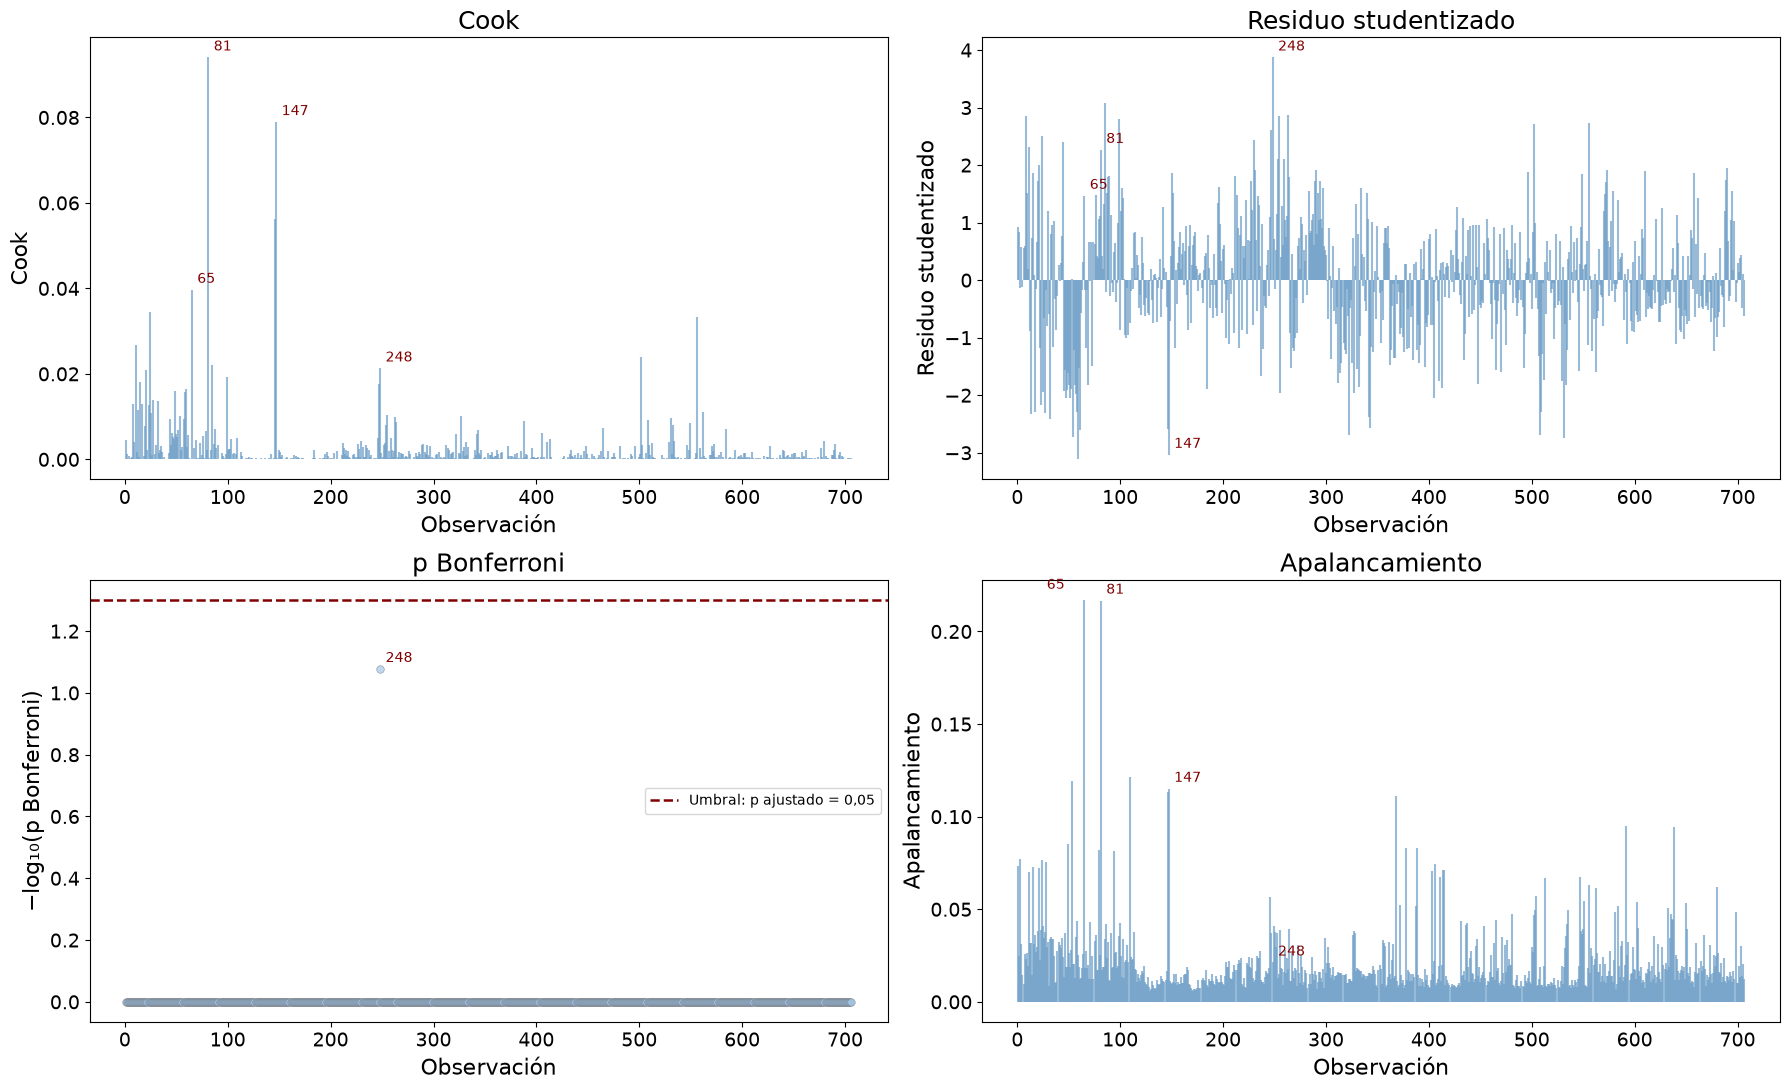

In [44]:
fig, axes = plt.subplots(2, 2, figsize=(18, 11))
for ax, columna in zip(axes.flat, influencia.columns):
    if columna == "p Bonferroni":
        valores = -np.log10(influencia[columna].clip(lower=np.finfo(float).tiny))
        significativos = influencia[columna] < 0.05
        _ = ax.scatter(influencia.index[~significativos], valores[~significativos],
                       s=30, color="#9fc3e4", edgecolor="#666666", linewidth=0.4, alpha=0.65)
        if significativos.any():
            _ = ax.scatter(influencia.index[significativos], valores[significativos],
                           s=60, color="#800000", edgecolor="white", linewidth=0.6,
                           label="p ajustado < 0,05")
        _ = ax.axhline(-np.log10(0.05), color="#800000", linestyle="--", linewidth=1.8,
                       label="Umbral: p ajustado = 0,05")
        _ = ax.set_ylabel("−log₁₀(p Bonferroni)")
        _ = ax.legend(fontsize=10)
    else:
        _ = ax.vlines(influencia.index, 0, influencia[columna], color="#6f9fc8", alpha=0.7)
        valores = influencia[columna]
        _ = ax.set_ylabel(columna)
    _ = ax.set(xlabel="Observación", title=columna)
    for observacion in [65, 81, 147, 248]:
        if columna == "p Bonferroni" and influencia.loc[observacion, columna] == 1:
            continue  # Los p-valores iguales a 1 quedan juntos en cero.
        desplazamiento = (-14, 8) if columna == "Apalancamiento" and observacion == 65 else (4, 5)
        alineacion = "right" if desplazamiento[0] < 0 else "left"
        _ = ax.annotate(str(observacion), (observacion, valores.loc[observacion]),
                        xytext=desplazamiento, textcoords="offset points", fontsize=10,
                        ha=alineacion, color="#800000")
    ax.title.set_fontsize(18)
    ax.xaxis.label.set_fontsize(16)
    ax.yaxis.label.set_fontsize(16)
    ax.tick_params(labelsize=14)
fig.tight_layout()
plt.show()

**Microejercicio — observaciones influyentes.** Identifica en una sola línea de código las tres observaciones con mayor distancia de Cook en `influencia`. ¿Coinciden necesariamente con las de mayor residuo?

In [45]:
# Pista: ordena de mayor a menor solo la columna de Cook de la tabla de influencia.
# Tu línea de código:

### Residuos, apalancamiento e influencia

Cada burbuja es una observación: el eje horizontal muestra su **apalancamiento**, el vertical su **residuo studentizado externo** y el tamaño representa la **distancia de Cook relativa al máximo observado**. Los trazos horizontales en $\pm2$ ayudan a localizar residuos llamativos; los verticales en $2p/n$ y $3p/n$ son referencias heurísticas de apalancamiento. Ninguna línea decide por sí sola qué hacer con un dato.

Activa las etiquetas y compara las observaciones 81 y 147, la 248 con residuo destacado y las 65 y 81 por su apalancamiento. Pregunta **dónde** está cada caso y **qué combinación** de residuo y apalancamiento explica el tamaño de su burbuja; después comprueba los valores reales en la tabla.

In [46]:
def grafico_influencia(etiquetas):
    fig, ax = plt.subplots(figsize=(16, 8))
    tamanos = 20 + 800 * influencia["Cook"] / influencia["Cook"].max()
    ax.scatter(influencia["Apalancamiento"], influencia["Residuo studentizado"],
               s=tamanos, color="#9fc3e4", alpha=0.65,
               edgecolors="#666666", linewidth=0.6)
    ax.axhline(0, color="#800000", linestyle="--", linewidth=1.8)
    for valor in [-2, 2]:
        ax.axhline(valor, color="#666666", linestyle=":", linewidth=1.2)
    for factor in [2, 3]:
        ax.axvline(factor * len(mod_lm5.params) / len(datos), color="#800000",
                   linestyle=":", linewidth=1.5)
    if etiquetas:
        for observacion in [65, 81, 147, 248]:
            fila = influencia.loc[observacion]
            ax.annotate(str(observacion), (fila["Apalancamiento"], fila["Residuo studentizado"]),
                        xytext=(6, 5), textcoords="offset points", fontsize=12,
                        color="#800000")
    ax.set(xlabel="Apalancamiento", ylabel="Residuo studentizado",
           title="Influencia de las observaciones")
    fig.tight_layout()
    plt.show()

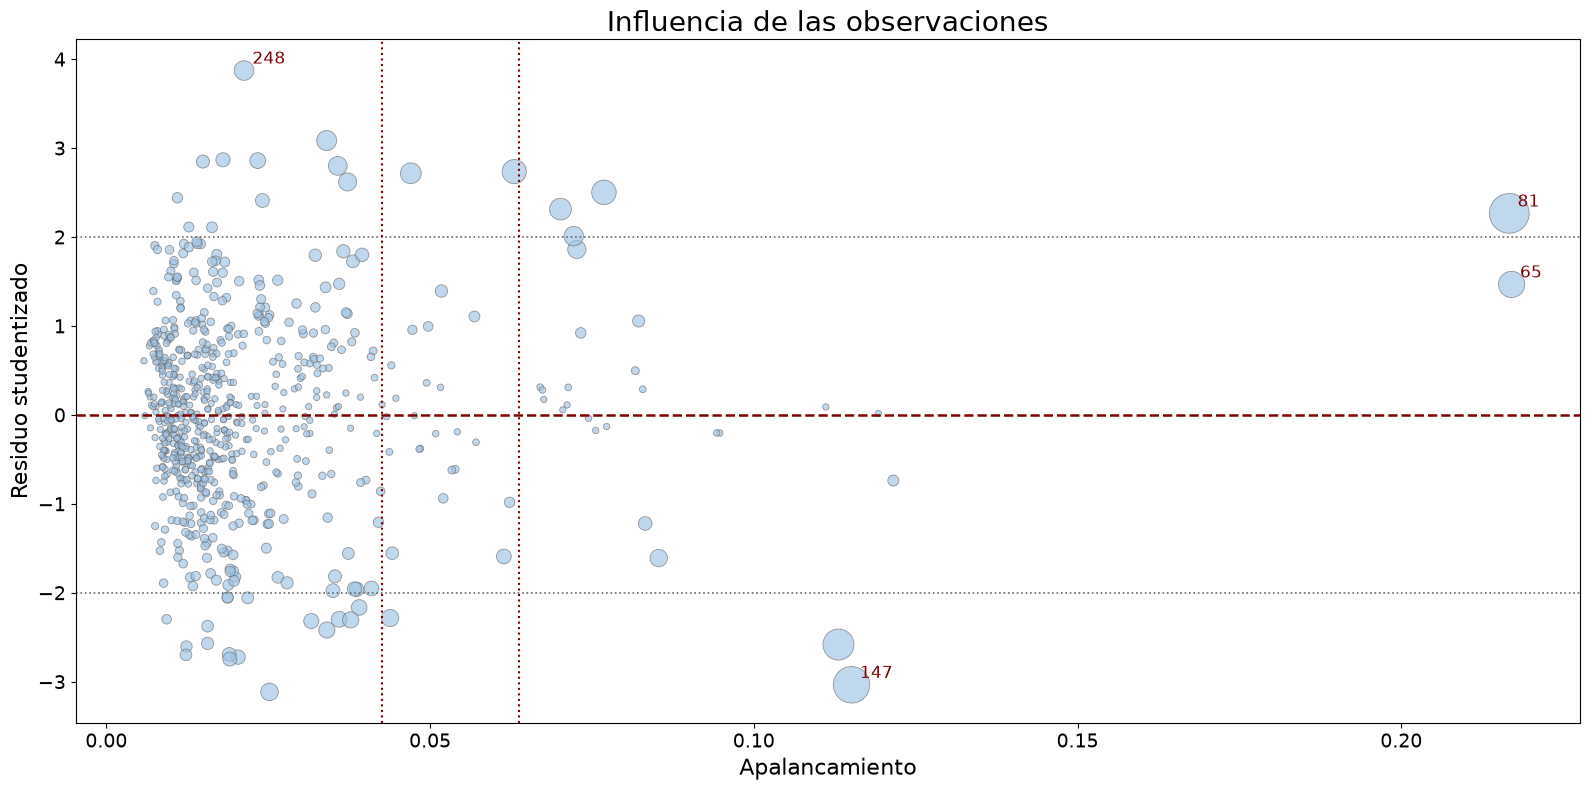

In [47]:
# True muestra las etiquetas de las observaciones destacadas.
grafico_influencia(True)

#### Inspeccionar las observaciones seleccionadas

`obs_rm` reúne las etiquetas 81, 147 y 248 para examinarlas con `datos.loc[obs_rm]`. Revisa las predictoras **y** la respuesta: ¿hay una combinación inusual, una edad extrema o un valor que podría ser una errata? `loc` busca etiquetas de fila, no posiciones; por eso coincide con los números señalados en los gráficos.

Aunque se llamen `obs_rm` en el código, **aún no se eliminan de `datos`**. Primero comprobamos su posición en todas las relaciones bivariantes. La observación 65 se muestra en el gráfico de influencia por su apalancamiento, pero no forma parte de esta lista de tres casos para el reajuste ilustrativo.

In [48]:
obs_rm = [81, 147, 248]
datos.loc[obs_rm]

,Cement,BlastFurnaceSlag,FlyAsh,Water,Superplasticizer,CoarseAggregate,FineAggregate,Age,Strength,Strength2
observacion,,,,,,,,,,
81,469.0,117.2,0.0,137.8,32.2,852.1,840.5,28,66.90,15.851582
147,168.0,42.1,163.8,121.8,5.7,1058.7,780.1,100,39.23,11.160340
248,451.0,0.0,0.0,165.0,11.3,1030.0,745.0,28,78.80,17.652869


#### Localizarlas en los gráficos de pares

En una nueva matriz de dispersión coloreamos y etiquetamos las observaciones 81, 147 y 248, mientras el resto queda en segundo plano. Esto ayuda a entender si cada caso es inusual **en una variable concreta** o solo en la **combinación de varias**; un punto puede parecer ordinario en cada gráfico por separado y aun así tener mucho apalancamiento multivariable.

Compara las etiquetas con `datos.loc[obs_rm]`. El color sirve únicamente para encontrarlas; no significa que se haya confirmado un error de medición ni que convenga borrarlas del análisis.

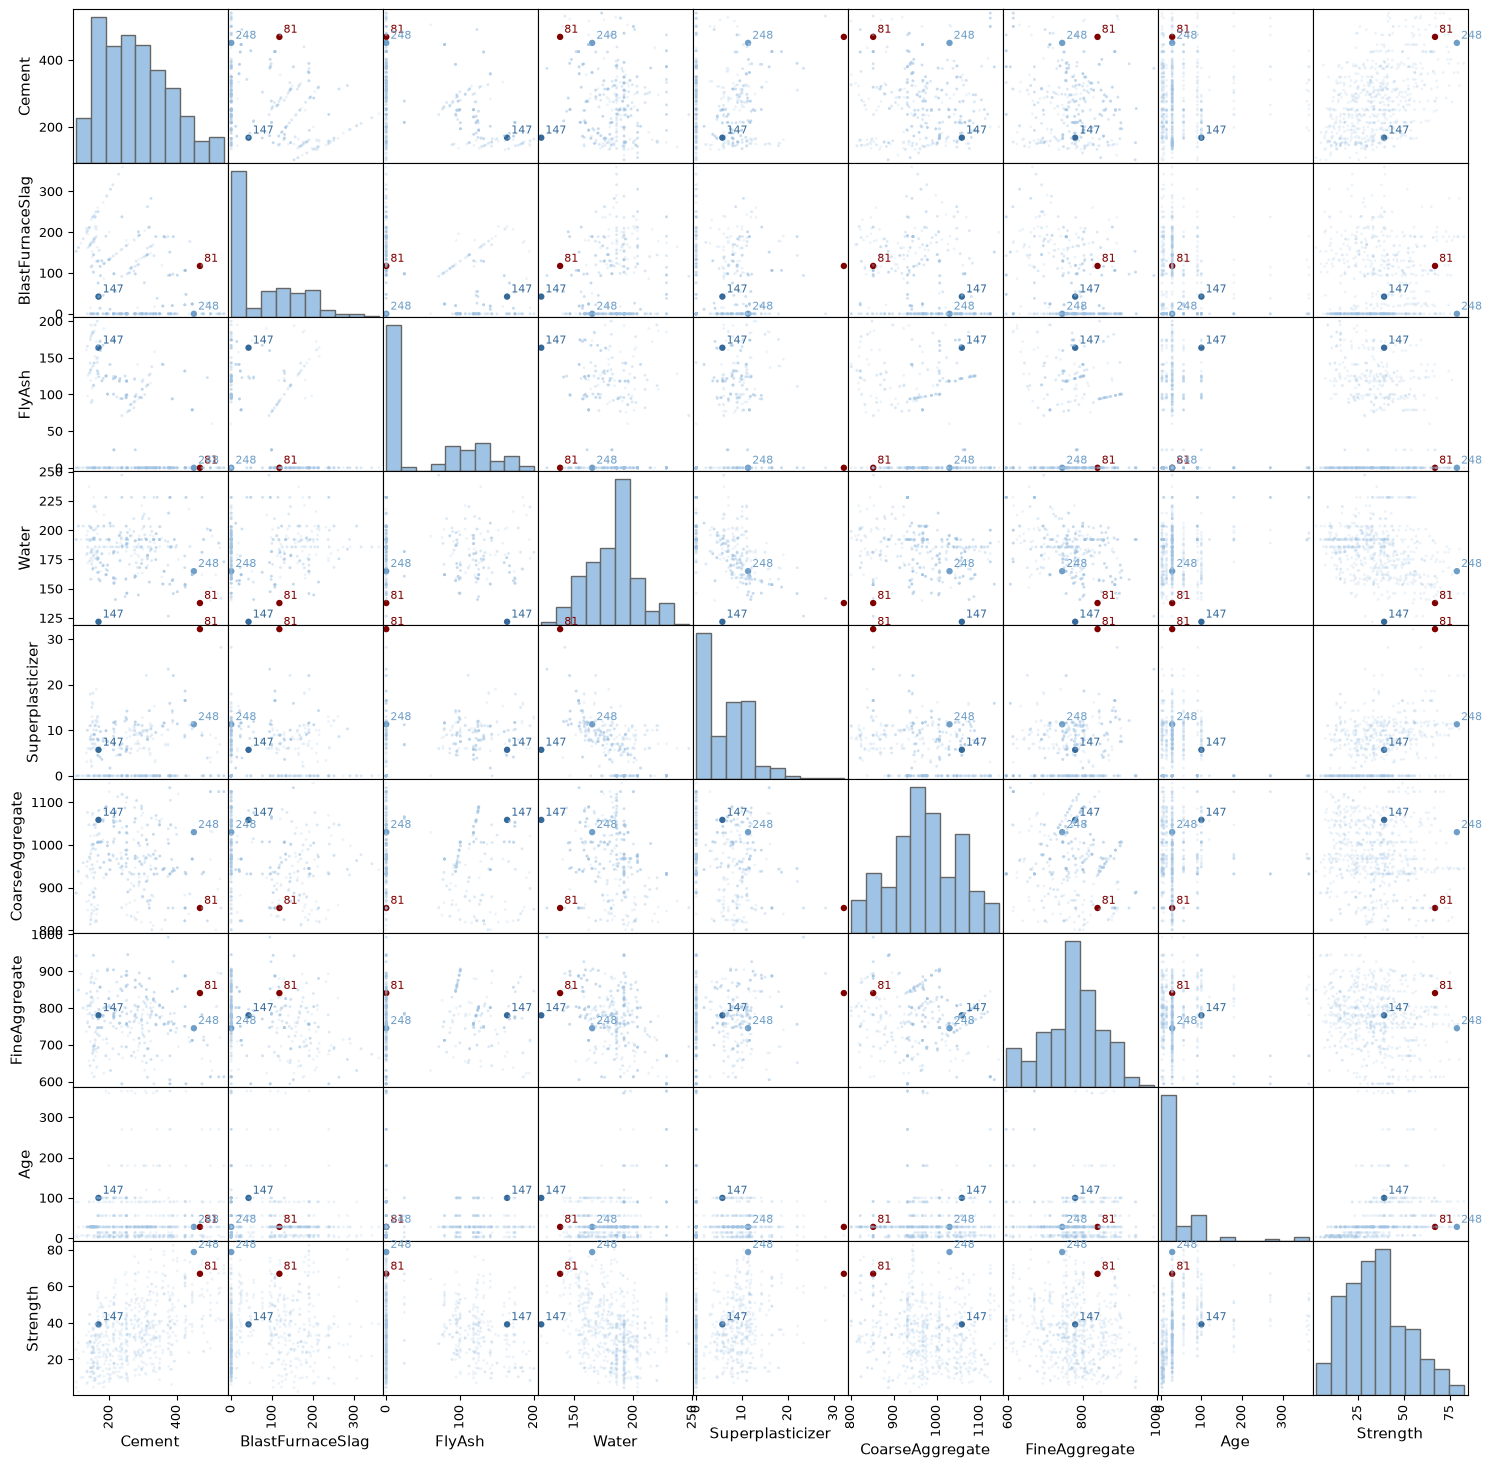

In [49]:
col_points = np.array(["#9fc3e433"] * len(datos), dtype=object)
tamanos = np.full(len(datos), 16.0)
colores_destacados = ["#800000", "#34699a", "#6f9fc8"]
for observacion, color in zip(obs_rm, colores_destacados):
    posicion = datos.index.get_loc(observacion)
    col_points[posicion] = color
    tamanos[posicion] = 85  # Destacan sin tapar los demás puntos.

axes = scatter_matrix(datos[columnas_originales], figsize=(18, 18), diagonal="hist",
                      c=col_points, s=tamanos, alpha=None,
                      hist_kwds={"color": "#9fc3e4", "edgecolor": "#666666"})
for i, variable_y in enumerate(columnas_originales):
    for j, variable_x in enumerate(columnas_originales):
        eje = axes[i, j]
        eje.tick_params(labelsize=9)
        eje.xaxis.label.set_fontsize(11)
        eje.yaxis.label.set_fontsize(11)
        if i != j:
            for observacion, color in zip(obs_rm, colores_destacados):
                _ = eje.annotate(str(observacion),
                                 (datos.loc[observacion, variable_x], datos.loc[observacion, variable_y]),
                                 xytext=(3, 3), textcoords="offset points", fontsize=8, color=color)
plt.show()

### Ajustar sin las observaciones señaladas: análisis de sensibilidad

Creamos **una copia** `datos_rm` excluyendo 81, 147 y 248; los datos originales quedan intactos. `mod_lm7` se reajusta sin ellas con las siete predictoras polinómicas utilizadas aquí, sin `CoarseAggregate`. El diseño vuelve a calcular medias y escalas en la muestra reducida, como corresponde a **un nuevo ajuste**. La celda siguiente vuelve a mostrar el resumen de `mod_lm5` para comparar estabilidad de coeficientes y resultados.

**Precaución:** `mod_lm7` no es un simple `mod_lm5` sin tres residuos: además de quitar filas, cambia los términos (excluye `CoarseAggregate`). Por tanto, una diferencia entre resúmenes **no puede atribuirse solo** a la eliminación de esas observaciones. Este apartado ilustra sensibilidad del ajuste, no una prueba de que debamos descartarlas; el modelo final conserva la muestra completa.

In [50]:
datos_rm = datos.drop(index=obs_rm).copy()
X_rm, _ = diseno_polinomico(datos_rm)
mod_lm7 = sm.OLS(datos_rm["Strength"], X_rm[columnas_sin_coarse]).fit()
mod_lm7.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               Strength   R-squared:                       0.786
Model:                            OLS   Adj. R-squared:                  0.781
Method:                 Least Squares   F-statistic:                     180.2
Date:                Wed, 21 Oct 2026   Prob (F-statistic):          4.33e-219
Time:                        12:12:14   Log-Likelihood:                -2419.3
No. Observations:                 703   AIC:                             4869.
Df Residuals:                     688   BIC:                             4937.
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 42.4395      0.712     59.623      0.000      41.042      43.837
Cement_1              11.0730      0.529     20.933      0.000      10.034      12.112
Cement_2              -0.2459      0.287     -0.858      0.391      -0.809       0.317
BlastFurnaceSlag_1     8.4354      0.558     15.113      0.000       7.340       9.531
BlastFurnaceSlag_2    -1.0710      0.324     -3.305      0.001      -1.707      -0.435
FlyAsh_1               3.6620      0.668      5.485      0.000       2.351       4.973
FlyAsh_2              -1.3157      0.496     -2.655      0.008      -2.289      -0.343
Water_1               -4.5350      0.459     -9.879      0.000      -5.436      -3.634
Water_2                1.0936      0.251      4.358      0.000       0.601       1.586
Superplasticizer_1     2.0073      0.595      3.375      0.001       0.840       3.175
Superplasticizer_2    -1.6227      0.262     -6.191      0.000      -2.137      -1.108
FineAggregate_1       -0.1013      0.428     -0.237      0.813      -0.941       0.739
FineAggregate_2       -1.1460      0.250     -4.583      0.000      -1.637      -0.655
Age_1                 16.9502      0.595     28.471      0.000      15.781      18.119
Age_2                 -3.0350      0.155    -19.600      0.000      -3.339      -2.731
==============================================================================
Omnibus:                        6.162   Durbin-Watson:                   1.454
Prob(Omnibus):                  0.046   Jarque-Bera (JB):                8.068
Skew:                          -0.055   Prob(JB):                       0.0177
Kurtosis:                       3.513   Cond. No.                         15.1
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [51]:
mod_lm5.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               Strength   R-squared:                       0.780
Model:                            OLS   Adj. R-squared:                  0.775
Method:                 Least Squares   F-statistic:                     174.8
Date:                Wed, 21 Oct 2026   Prob (F-statistic):          5.13e-216
Time:                        12:12:14   Log-Likelihood:                -2443.2
No. Observations:                 706   AIC:                             4916.
Df Residuals:                     691   BIC:                             4985.
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 42.5715      0.724     58.804      0.000      41.150      43.993
Cement_1              11.1079      0.540     20.584      0.000      10.048      12.167
Cement_2              -0.2087      0.293     -0.711      0.477      -0.785       0.367
BlastFurnaceSlag_1     8.2761      0.566     14.626      0.000       7.165       9.387
BlastFurnaceSlag_2    -1.0406      0.329     -3.163      0.002      -1.687      -0.395
FlyAsh_1               3.5449      0.674      5.258      0.000       2.221       4.868
FlyAsh_2              -1.3868      0.505     -2.749      0.006      -2.377      -0.396
Water_1               -4.2486      0.462     -9.206      0.000      -5.155      -3.342
Water_2                0.8950      0.250      3.577      0.000       0.404       1.386
Superplasticizer_1     2.3836      0.602      3.961      0.000       1.202       3.565
Superplasticizer_2    -1.4588      0.249     -5.853      0.000      -1.948      -0.969
FineAggregate_1       -0.1411      0.435     -0.324      0.746      -0.995       0.713
FineAggregate_2       -1.1586      0.252     -4.602      0.000      -1.653      -0.664
Age_1                 16.8270      0.605     27.812      0.000      15.639      18.015
Age_2                 -3.0037      0.157    -19.112      0.000      -3.312      -2.695
==============================================================================
Omnibus:                        7.982   Durbin-Watson:                   1.401
Prob(Omnibus):                  0.018   Jarque-Bera (JB):               11.698
Skew:                           0.024   Prob(JB):                      0.00288
Kurtosis:                       3.629   Cond. No.                         15.0
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### Modelo final

Asignamos `mod_final = mod_lm5`: el modelo polinómico seleccionado **con todas las observaciones de entrenamiento** y respuesta `Strength` en la escala original. Los modelos con respuesta transformada y con filas excluidas fueron análisis complementarios; no los usamos para predecir en test.

Este punto fija la decisión **antes de consultar los resultados de test**. A partir de aquí se puede interpretar el modelo y comprobar cuánto error comete en datos nuevos, pero no cambiar su especificación solo porque el test resulte mejor o peor: eso convertiría la evaluación en parte del entrenamiento.

In [52]:
mod_final = mod_lm5

### Efectos de cada predictor en el modelo final

Para visualizar cada relación ajustada, `datos_efecto(variable)` crea una rejilla de 100 valores entre el mínimo y el máximo observados de esa predictora. Forma nuevas filas del **diseño del modelo** variando las columnas lineal y cuadrática de esa variable y dejando las otras columnas en sus medias del entrenamiento; luego obtiene la predicción media y su **intervalo de confianza del 95 %** mediante `get_prediction`.

La línea muestra la resistencia media estimada en este escenario y la banda, la incertidumbre de esa **media**, no el rango esperado de una pieza individual (eso requeriría un intervalo de predicción). Las columnas cuadráticas de las otras variables se fijan en sus propias medias, que no equivalen necesariamente al cuadrado de una media: la combinación dibujada es un **perfil de diseño** y puede no coincidir exactamente con una receta de hormigón real. Evita interpretarlo como efecto causal.

La cuadrícula enseña todos los términos seleccionados; debajo puedes cambiar `variable` o desactivar `banda` para examinar uno con más detalle. No extrapoles estas curvas más allá del rango mostrado.

In [53]:
def datos_efecto(variable):
    valores = np.linspace(datos[variable].min(), datos[variable].max(), 100)
    columnas = mod_final.model.exog_names
    medias = mod_final.model.exog.mean(axis=0)
    matriz = pd.DataFrame(np.tile(medias, (len(valores), 1)), columns=columnas)
    if variable in parametros_polinomicos:
        centro, escala = parametros_polinomicos[variable]
        z = (valores - centro) / escala
        matriz[grupos_polinomicos[variable]] = np.column_stack((z, z ** 2))
    else:
        matriz[variable] = valores
    resumen = mod_final.get_prediction(matriz).summary_frame(alpha=0.05)
    return valores, resumen

def dibujar_efecto(ax, variable, banda=True):
    valores, resumen = datos_efecto(variable)
    if banda:
        ax.fill_between(valores, resumen["mean_ci_lower"].to_numpy(), resumen["mean_ci_upper"].to_numpy(),
                        color="#9fc3e4", alpha=0.5, label="IC de la media (95 %)")
    ax.plot(valores, resumen["mean"].to_numpy(), color="#800000", linewidth=1.8)
    ax.set(xlabel=variable, ylabel="Strength predicha", title=variable)

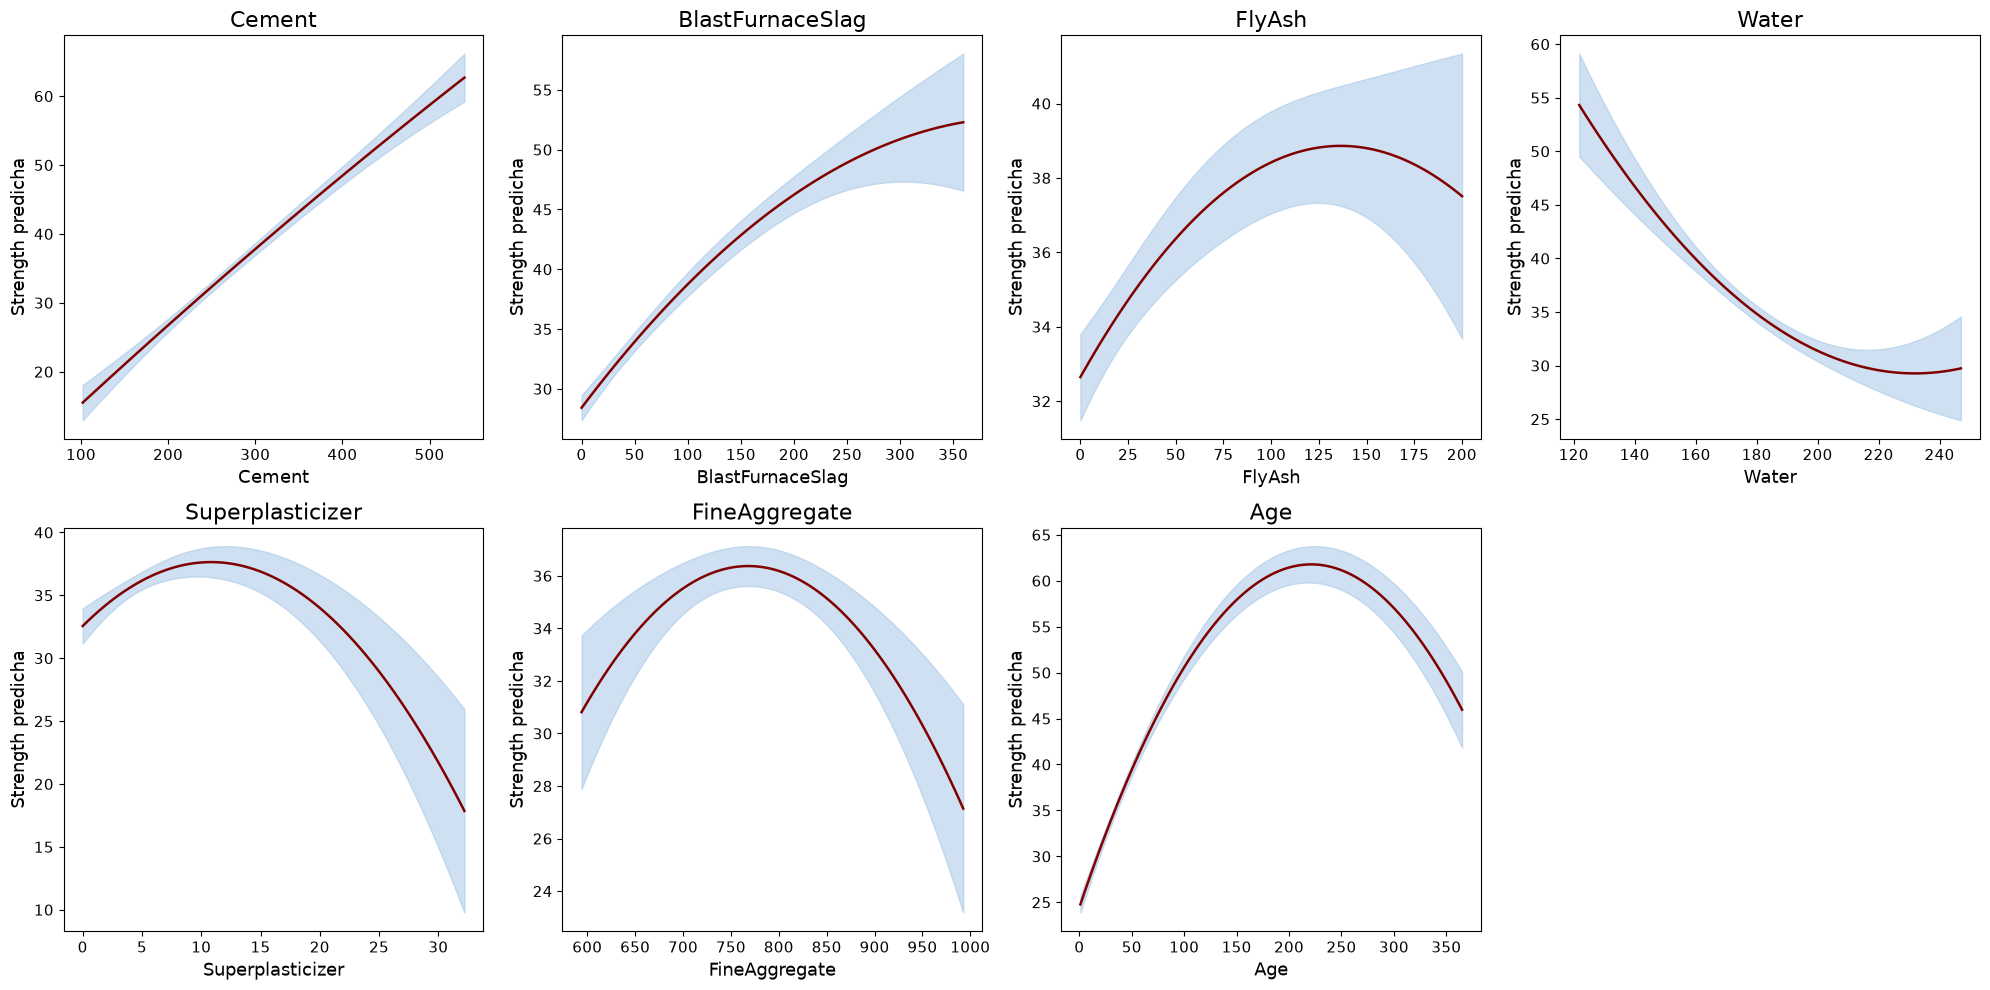

In [54]:
filas_efectos = int(np.ceil(len(seleccion_polinomica) / 4))
fig, axes = plt.subplots(filas_efectos, 4, figsize=(20, 5 * filas_efectos), squeeze=False)
for ax, variable in zip(axes.flat, seleccion_polinomica):
    dibujar_efecto(ax, variable)
    ax.title.set_fontsize(16)
    ax.xaxis.label.set_fontsize(13)
    ax.yaxis.label.set_fontsize(13)
    ax.tick_params(labelsize=11)
for ax in list(axes.flat)[len(seleccion_polinomica):]:
    ax.set_visible(False)
fig.tight_layout()
plt.show()

Examinamos con más detalle el primer predictor seleccionado por el modelo. Puedes cambiar el predictor o quitar la banda de confianza modificando los argumentos de la llamada siguiente.

In [55]:
def explorar_efecto(variable, banda):
    fig, ax = plt.subplots(figsize=(16, 8))
    dibujar_efecto(ax, variable, banda)
    fig.tight_layout()
    plt.show()

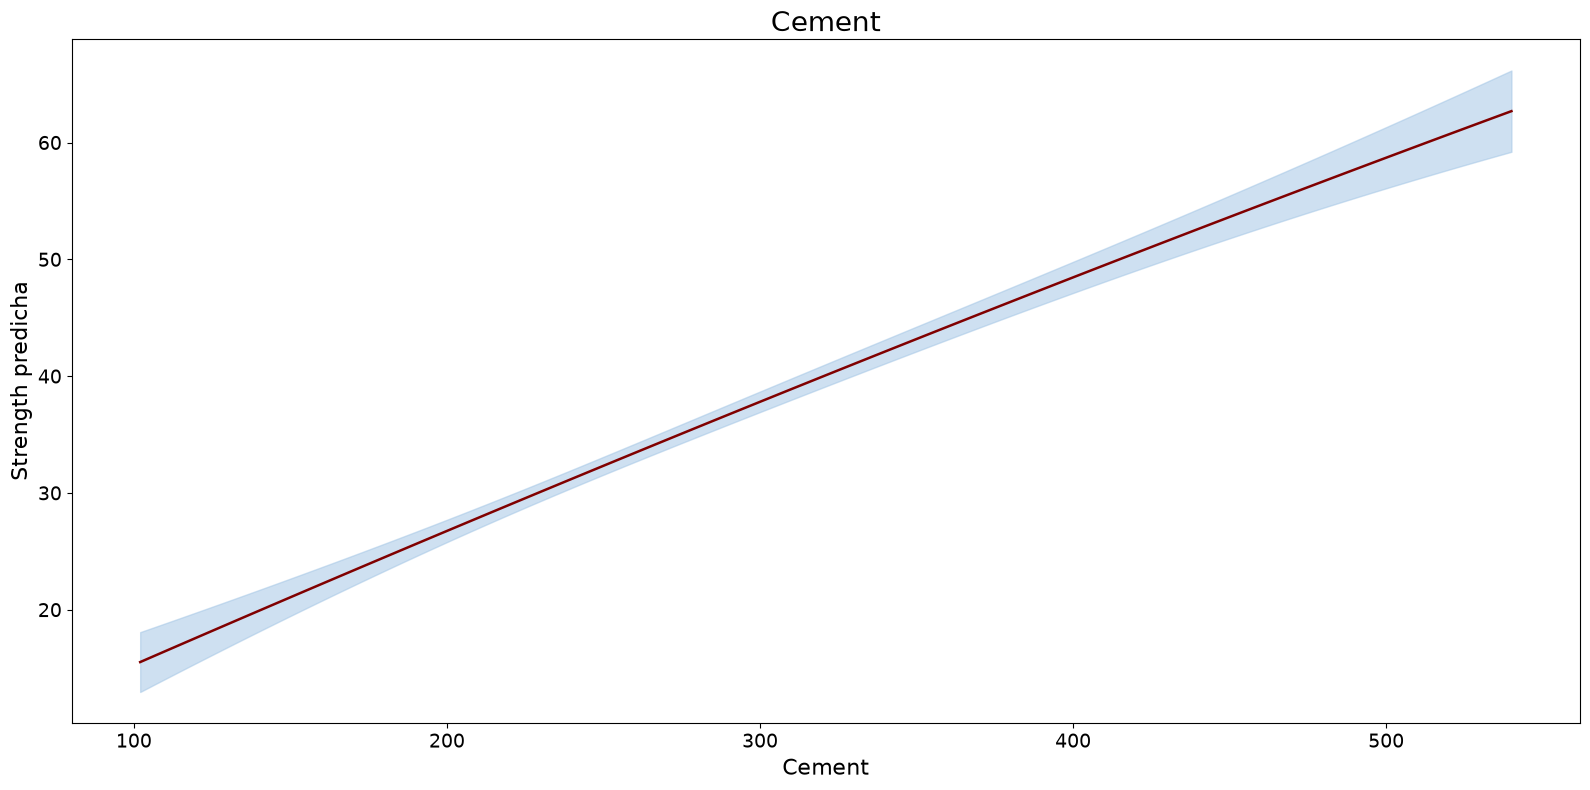

In [56]:
# Cambia seleccion_polinomica[0] por otro predictor seleccionado, o True por False.
explorar_efecto(seleccion_polinomica[0], True)

## Evaluar con nuevos datos

### Leer el conjunto de test

Hasta ahora **ajustamos y seleccionamos con entrenamiento**. El archivo de test contiene casos distintos, reservados para comprobar cómo generaliza el modelo elegido. Lo leemos con el mismo separador y numeramos sus filas desde 1 para poder seleccionar un caso mediante `loc`.

El código crea también `Strength2` usando la `lamb` aprendida en entrenamiento, para mantener disponible la transformación estudiada; **`mod_final` no utiliza esa columna**: predice `Strength` en su escala original. No recalcules `lamb` ni el preprocesamiento polinómico con el test y no uses sus valores observados para reajustar el modelo. Su respuesta solo se consultará al representar y cuantificar los errores.

In [57]:
test = pd.read_csv(DATA_PATH / "Concrete_test.txt", sep="\t")
test.index = np.arange(1, len(test) + 1)
test.index.name = "observacion"
test["Strength2"] = transformar_respuesta(test["Strength"], lamb)

### Construir y obtener las predicciones

`diseno_polinomico(test, parametros_polinomicos)` aplica a cada predictor de test **las medias y escalas guardadas durante el entrenamiento**. El orden de columnas importa: `X_test[mod_final.model.exog_names]` selecciona exactamente las variables que espera el modelo final y en el mismo orden. Después, `predict` calcula una resistencia estimada por observación; `pr` conserva el índice de test para emparejar cada predicción con su respuesta real.

El modelo aún **no ha usado `Strength` de test** en esta operación. Comprueba el número y el rango de las predicciones: valores extraños pueden revelar entradas fuera del dominio de entrenamiento o un error de preprocesamiento, no necesariamente un fallo del algoritmo de ajuste.

In [58]:
X_test, _ = diseno_polinomico(test, parametros_polinomicos)
pr = mod_final.predict(X_test[mod_final.model.exog_names]).rename("Prediccion")
pr

observacion
1      54.618238
2      54.618238
3      57.599832
4      43.607684
5      25.211815
         ...    
320    39.600875
321    24.530078
322    34.337210
323    44.336446
324    29.039781
Name: Prediccion, Length: 324, dtype: float64

### Predicciones y valores observados: un caso a la vez

Cada punto del gráfico compara una **predicción de test (eje horizontal)** con la resistencia observada (eje vertical). La diagonal representa coincidencia exacta: por encima, el modelo **subestimó** la resistencia; por debajo, la **sobreestimó**. La observación elegida destaca en granate y la tabla de la derecha muestra sus predictoras originales, su valor real, la predicción y el residuo **real menos predicho**.

Sobre la coordenada horizontal del caso aparecen dos intervalos estimados por el modelo entrenado: el **IC del 95 % para la respuesta media** de observaciones con esas predictoras y el **IP del 95 % para una observación individual**. El IP suele ser más ancho porque incorpora la dispersión de las respuestas individuales, además de la incertidumbre sobre su media. **Ninguno se calcula a partir del valor real de test del caso mostrado**; la posición del punto real permite compararlos visualmente, pero que un único punto caiga fuera del IP no invalida el modelo por sí solo.

Desliza el control o escribe la etiqueta de observación para explorar otros casos. Si el widget no aparece en tu editor, ejecuta `explorar_prediccion(5)` cambiando el número.

In [66]:
from base64 import b64encode
from io import BytesIO
from IPython.display import HTML as HTMLDisplay


def explorar_prediccion(observacion):
    intervalo = mod_final.get_prediction(
        X_test.loc[[observacion], mod_final.model.exog_names]
    ).summary_frame(alpha=0.05).iloc[0]
    predicho = pr.loc[observacion]
    observado = test.loc[observacion, "Strength"]

    fig, ax = plt.subplots(figsize=(8, 7))
    ax.scatter(pr, test["Strength"], s=40, color="#9fc3e4", alpha=0.65,
               edgecolors="#666666", linewidths=0.4, label="Observaciones de test", zorder=2)
    minimo = min(pr.min(), test["Strength"].min(), intervalo["obs_ci_lower"])
    maximo = max(pr.max(), test["Strength"].max(), intervalo["obs_ci_upper"])
    margen = (maximo - minimo) * 0.05
    ax.plot([minimo, maximo], [minimo, maximo], color="#800000", linewidth=1.8,
            label="Predicción = observación", zorder=1)
    ax.vlines(predicho, intervalo["obs_ci_lower"], intervalo["obs_ci_upper"],
              color="#9fc3e4", linewidth=11, alpha=0.95,
              label="IP individual (95 %)", zorder=3)
    ax.vlines(predicho, intervalo["mean_ci_lower"], intervalo["mean_ci_upper"],
              color="#34699a", linewidth=5, label="IC de la media (95 %)", zorder=4)
    ax.scatter(predicho, observado, s=150, color="#800000", edgecolors="white",
               linewidths=2, label=f"Observación {observacion}", zorder=5)
    ax.annotate(f"{observacion}", (predicho, observado), xytext=(10, 10),
                textcoords="offset points", fontsize=12, fontweight="bold", color="#800000",
                bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85, "pad": 2})
    ax.set(xlim=(minimo - margen, maximo + margen),
           ylim=(minimo - margen, maximo + margen))
    ax.set_xlabel("Resistencia predicha (MPa)", fontsize=16)
    ax.set_ylabel("Resistencia observada (MPa)", fontsize=16)
    ax.set_title(f"Predicción en test · observación {observacion}", fontsize=20, pad=18)
    ax.set_aspect("equal", adjustable="box")
    ax.tick_params(labelsize=14)
    ax.grid(color="#b0b0b0", alpha=0.25, linewidth=0.8)
    ax.legend(loc="upper left", fontsize=10, framealpha=0.95)
    fig.tight_layout()

    tabla = test.loc[[observacion], columnas_originales].assign(
        Prediccion=predicho, Residuo=observado - predicho,
        IC_media_inf=intervalo["mean_ci_lower"], IC_media_sup=intervalo["mean_ci_upper"],
        IP_individual_inf=intervalo["obs_ci_lower"], IP_individual_sup=intervalo["obs_ci_upper"],
    ).T
    imagen = BytesIO()
    fig.savefig(imagen, format="png", dpi=110, bbox_inches="tight")
    plt.close(fig)
    tabla_html = tabla.to_html(header=False, border=0, float_format=lambda valor: f"{valor:.2f}")
    return HTMLDisplay(
        "<style>.prediccion-detalle table {border-collapse: collapse; width: 100%; "
        "color: #333; font-size: 13px;}"
        ".prediccion-detalle th, .prediccion-detalle td {padding: 5px 8px; "
        "border-bottom: 1px solid #ddd; text-align: right;}"
        ".prediccion-detalle th {text-align: left; color: #34699a; font-weight: 600;}"
        ".prediccion-detalle tr:nth-child(even) {background: #f3f7fb;}</style>"
        "<div style='display: flex; flex-wrap: wrap; gap: 18px; align-items: flex-start;'>"
        "<div style='flex: 2 1 520px; min-width: 0;'>"
        f"<img src='data:image/png;base64,{b64encode(imagen.getvalue()).decode()}' "
        f"alt='Predicciones en test para la observación {observacion}' "
        "style='display: block; width: 100%; height: auto;'></div>"
        "<div class='prediccion-detalle' style='flex: 1 1 260px; min-width: 0;'>"
        f"<h4 style='margin: 12px 0; color: #800000;'>Observación {observacion}</h4>"
        f"{tabla_html}</div></div>"
    )

In [67]:
from ipywidgets import BoundedIntText, HBox, HTML, IntSlider, Layout, VBox, link

selector_predicciones = IntSlider(
    value=5, min=int(test.index.min()), max=int(test.index.max()), step=1,
    description="Observación", continuous_update=False, readout=False,
    style={"description_width": "105px"}, layout=Layout(width="520px"),
)
numero_predicciones = BoundedIntText(
    value=5, min=selector_predicciones.min, max=selector_predicciones.max,
    description="Ir al n.º", style={"description_width": "65px"},
    layout=Layout(width="170px"),
)
enlace_predicciones = link((selector_predicciones, "value"), (numero_predicciones, "value"))
visor_predicciones = HTML(value=explorar_prediccion(selector_predicciones.value).data,
                          layout=Layout(width="100%"))

def actualizar_prediccion(cambio):
    visor_predicciones.value = explorar_prediccion(cambio["new"]).data

selector_predicciones.observe(actualizar_prediccion, names="value")
control_predicciones = VBox([
    HTML("<div style='border-left: 4px solid #800000; padding: 8px 12px; "
         "font-size: 18px; font-weight: 600;'>Explora las predicciones en test</div>"),
    HBox([selector_predicciones, numero_predicciones], layout=Layout(align_items="center")),
    visor_predicciones,
], layout=Layout(width="100%", gap="12px"))
display(control_predicciones)

### Error de predicción en test

Para cada observación, el error de predicción puede escribirse como $\widehat y_i-y_i$; cambiar el signo no afecta a su cuadrado ni a su valor absoluto. El **error cuadrático medio** es $\mathrm{EQM}=\frac1n\sum_i(\widehat y_i-y_i)^2$. En el código, `n` cuenta las filas de test y `pr` y `test["Strength"]` se emparejan por su índice. El EQM penaliza mucho los errores grandes, pero sus unidades son $\mathrm{MPa}^2$, menos intuitivas.

Tomamos la raíz: $\mathrm{RMSE}=\sqrt{\mathrm{EQM}}$, de nuevo en **MPa**. Por ejemplo, un RMSE mayor indica errores cuadráticos típicos mayores en este test; no es la precisión garantizada para cada futura observación. Calculamos aquí estas dos medidas y después reunimos también MAE, MAPE y $R^2$ de test. Ninguna cifra reemplaza la inspección de casos individuales y posibles sesgos sistemáticos.

In [61]:
n = test.shape[0]
EQM = ((pr - test["Strength"]) ** 2).sum() / n
EQM

np.float64(72.96828037227964)

In [62]:
RMSE = np.sqrt(EQM)
RMSE

np.float64(8.542147292822785)

**Microejercicio — error absoluto en test.** Calcula en una sola línea de código el error absoluto medio (MAE) entre `pr` y `test["Strength"]`. ¿En qué unidades se expresa? Compáralo con `RMSE`, que da más peso a los errores grandes.

In [63]:
# Pista: compara pr y test["Strength"] sin elevar al cuadrado; usa el valor absoluto antes de promediar.
# Tu línea de código:

### Resumen de métricas en test

Comprueba tu MAE del microejercicio con la tabla: $\mathrm{MAE}=\frac1n\sum_i|\widehat y_i-y_i|$ también se expresa en **MPa**, pero crece menos que el RMSE ante errores muy grandes. **Antes de ejecutar la celda de resumen**, completa la celda del microejercicio para definir `MAE` si has reiniciado el kernel.

El **MAPE** promedia $100|\widehat y_i-y_i|/|y_i|$ y se expresa en porcentaje. Solo tiene sentido cuando las respuestas observadas son distintas de cero; el código devuelve `NaN` si alguna vale cero, y cerca de cero puede resultar engañoso. El **$R^2$ de test** compara la suma de errores cuadrados del modelo con la de predecir siempre la media observada de este test **solo como referencia de evaluación**. Puede ser **negativo** si el modelo empeora esa referencia; no es un parámetro que se ajuste con el test.

Para contextualizar RMSE y MAE, las dos celdas siguientes muestran la desviación típica y los cuantiles de `Strength` observada en test. Son descripciones de esa muestra, no puntuaciones de calidad del modelo. No uses estas métricas para volver atrás y elegir otro modelo con el mismo test.

In [69]:
observados = test["Strength"]
errores = pr - observados
MAPE = np.nan if (observados == 0).any() else (100 * errores.abs() / observados.abs()).mean()
R2_test = 1 - (errores ** 2).sum() / ((observados - observados.mean()) ** 2).sum()
pd.Series({"EQM": EQM, "RMSE": RMSE, "MAPE (%)": MAPE, "R² test": R2_test},
          name="Evaluación en test").to_frame()

,Evaluación en test
EQM,72.968280
RMSE,8.542147
MAPE (%),23.893533
R² test,0.753938


La desviación típica observada describe la variabilidad de la resistencia antes de usar las predicciones.

In [ ]:
test["Strength"].std(ddof=1)

In [ ]:
test["Strength"].describe()

### Ejercicio 3.2 — Comparar predicciones en test

Ya conocemos el `RMSE` del modelo final sobre observaciones que no se utilizaron en su ajuste. Compáralo con un **referente sencillo previamente entrenado**, `mod_lm0`, sin cambiar los modelos ni `pr`:

1. Construye para `test` la misma matriz que usó `mod_lm0`: columna constante y `Cement`, en ese orden. Pasa esa matriz a `mod_lm0.predict(...)` y guarda las predicciones con **otro nombre**. No incluyas los demás predictores, porque ese modelo no los conoce.
2. Calcula el RMSE de esas nuevas predicciones frente a `test["Strength"]` y compáralo con `RMSE`. Ambos errores estarán en **MPa** y se medirán sobre las **mismas filas**: así la comparación responde a cuál predice mejor en este conjunto de test.

¿Por qué no basta con comparar el $R^2$ de entrenamiento? Porque mide ajuste en los datos usados para estimar los coeficientes, no error en observaciones nuevas. **No reajustes ni selecciones** modelos según este test: repetir elecciones sobre él haría optimista la evaluación. Si el modelo más complejo no gana aquí, piensa en sobreajuste, incertidumbre y el tamaño de esta muestra antes de generalizar la conclusión.

In [ ]:
# 3.2.1 — Predecir la resistencia de test con el modelo simple.
# Pista: construye la misma matriz con constante y Cement que en X_simple.
# Guarda las nuevas predicciones con otro nombre; conserva pr sin cambios.
# Tu código:

In [ ]:
# 3.2.2 — Comparar el error cuadrático medio en test.
# Pista: calcula el RMSE de las nuevas predicciones y compáralo con RMSE del modelo final.
# No reajustes ni elijas modelos basándote en este conjunto de test.
# Tu código:

### Documentación de las herramientas

- [Regresión por mínimos cuadrados en statsmodels](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.OLS.html).
- [Suavizado LOWESS](https://www.statsmodels.org/stable/generated/statsmodels.nonparametric.smoothers_lowess.lowess.html).
- [Transformación Box–Cox en SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.special.boxcox.html).